In [2]:
import pandas as pd
import numpy as np
import pickle
import json
from pathlib import Path
import matplotlib.pyplot as plt
from dataclasses import dataclass
from tqdm.auto import tqdm

from scipy.stats import kruskal, mannwhitneyu
from itertools import combinations
from statsmodels.stats.multitest import multipletests

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
from scipy.spatial import ConvexHull, distance
import skeliner as sk

In [3]:
TRIAL="trial3"

## Exploring the Skeletons

In [4]:
config_path = f"../configs/{TRIAL}.json"
with open(config_path, "r") as f:
    config = json.load(f)

In [ ]:
@dataclass
class Skeleton:
    features: np.ndarray
    # projections: object
    neighbors: dict



skeletons_path = Path(config['data']['path']) / "skeletons"
data_path = Path(config['data']['path']) 

skeletons = {}

for cell_dir in skeletons_path.iterdir():

    if not cell_dir.is_dir():
        continue

    cell_id = cell_dir.name

    try:
        features = np.load(cell_dir / "features.npy")

        with open(cell_dir / "neighbors.pkl", "rb") as f:
            neighbors = pickle.load(f)

        # projections_path = cell_dir / "projections.npy"

        # if projections_path.exists():
        #     projections = np.load(projections_path)
        # else:
        #     projections = np.nan

        skeletons[cell_id] = Skeleton(
            features=features,
            # projections=projections,
            neighbors=neighbors
        )

    except Exception as e:
        print(f"ERROR for {cell_id}: {type(e).__name__}: {e}")

print(f"Loaded {len(skeletons)} cells")

KeyboardInterrupt: 

In [ ]:
cell_meta = pd.read_csv(data_path / "cell_meta.csv")
cell_meta["cell_id"] = cell_meta["cell_id"].astype(str)

In [10]:
cell_meta.describe()

,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,soma_x_um,soma_y_um,soma_z_um
count,3690.000000,3690.000000,3690.000000,3690.000000,3690.000000,3690.000000,3690.0,3690.000000,3690.000000,3690.000000
mean,582.635564,636.825664,-14.843868,10943.124390,9969.625745,973.498645,0.0,582.635566,636.825665,-14.843868
std,273.149330,243.957688,2.729649,4510.641906,4456.278675,627.146617,0.0,273.149329,243.957697,2.729649
min,61.421330,96.857229,-35.182064,2008.000000,1069.000000,0.000000,0.0,61.421300,96.857200,-35.182100
25%,356.930547,438.019072,-15.907489,7236.750000,6249.500000,629.250000,0.0,356.930500,438.018750,-15.907475
50%,580.981712,631.303358,-14.635529,10295.500000,9470.000000,992.000000,0.0,580.981500,631.303000,-14.635500
75%,808.895194,836.330863,-13.585086,14165.250000,13188.750000,1102.750000,0.0,808.895250,836.330500,-13.585075
max,1104.268869,1100.130890,30.609562,26202.000000,24590.000000,4494.000000,0.0,1104.270000,1100.130000,30.609600


In [11]:
cell_meta.describe(include='object')

,cell_id,cellclass_final,celltype_final,celltype_final_decision
count,3690,3690,2915,3022
unique,3690,1,39,4
top,720575940537162675,RGC,F-mini-ON,both_strong
freq,1,3690,235,1627


In [12]:
cell_meta['celltype_final_decision'].unique()

array([nan, 'both_strong', 'both_weak', 'classifier', 'conflict'],
      dtype=object)

In [13]:
cell_meta['celltype_final'].unique()

array([nan, 'ON alpha',
       'Sustained suppressed-by-contrast strong surround EW28',
       'ON delayed', 'OFF vertical OS - asymmetric', 'EW25', 'F-mini-OFF',
       'F-mini-ON', 'UHD', 'Bursty suppressed by contrast',
       'ON-OFF DS - direction unknown', 'ON-OFF DS - ventral',
       'ON vertical OS small RF', 'OFF transient small RF', 'M6', 'HD2',
       'ON DS sustained - direction unknown', 'HD1',
       'OFF sustained EW1no', 'OFF sustained EW3o', 'EW82', 'EW5to',
       'PixON', 'OFF sustained alpha', 'ON transient medium RF',
       'OFF transient medium RF', 'EW915', 'ON transient small RF',
       'ON bursty', 'Local edge detector', 'OFF transient alpha', 'EW85',
       'M2', 'ON transient EW6t',
       'Sustained suppressed-by-contrast no surround EW27', 'M1', 'DAC',
       'ON OS small RF - orientation unknown', 'ON SAC', 'm8:X'],
      dtype=object)

In [16]:
selected_celltypes = ["HD2", 'HD1', 'ON transient small RF', 'OFF transient small RF', 'UHD']

Number of cell types: 5
Number of cells: 631


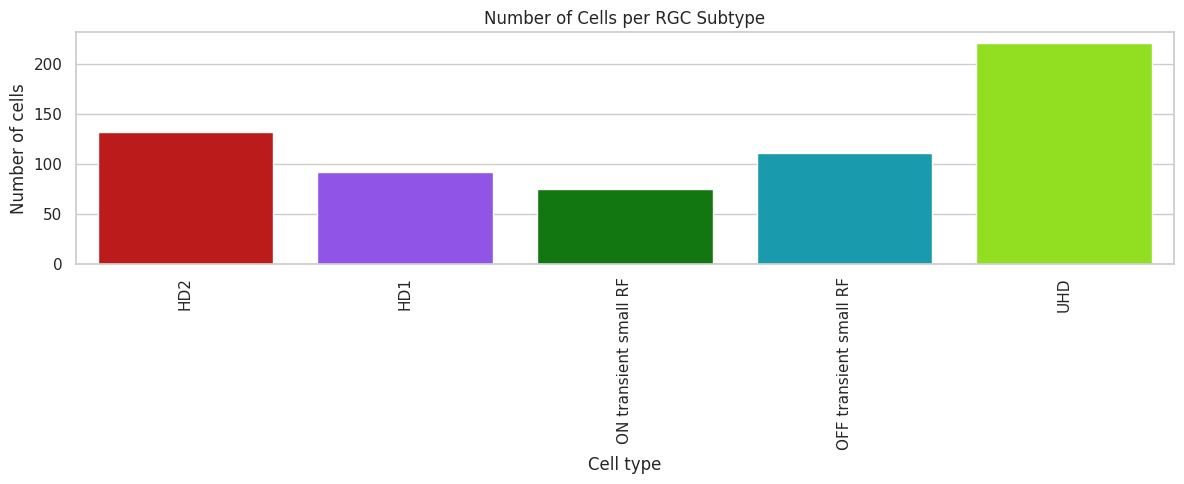


Morphological features being compared:
['n_nodes', 'n_axon_nodes', 'n_stitched_edges', 'n_axon_nodes_ratio']


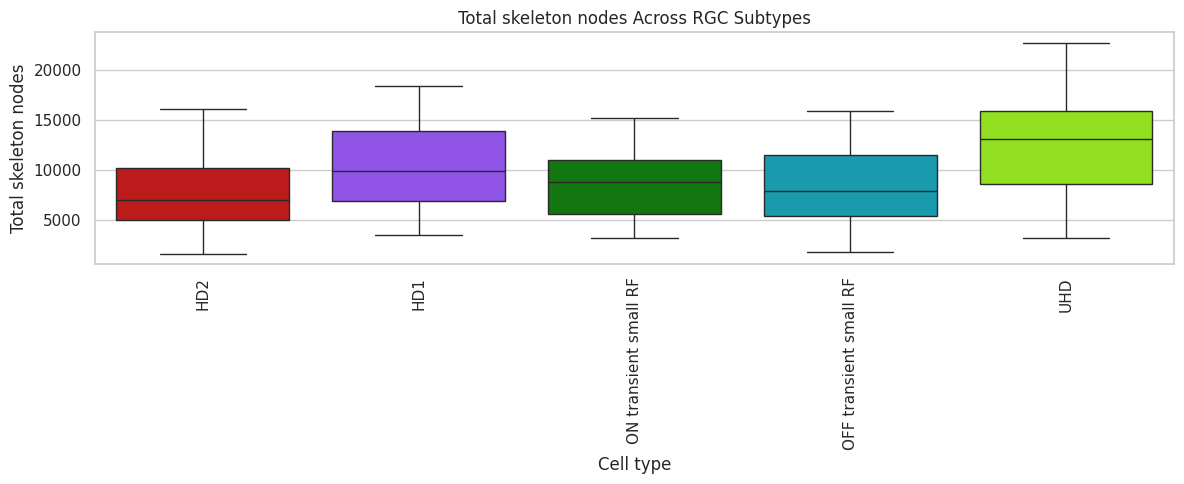

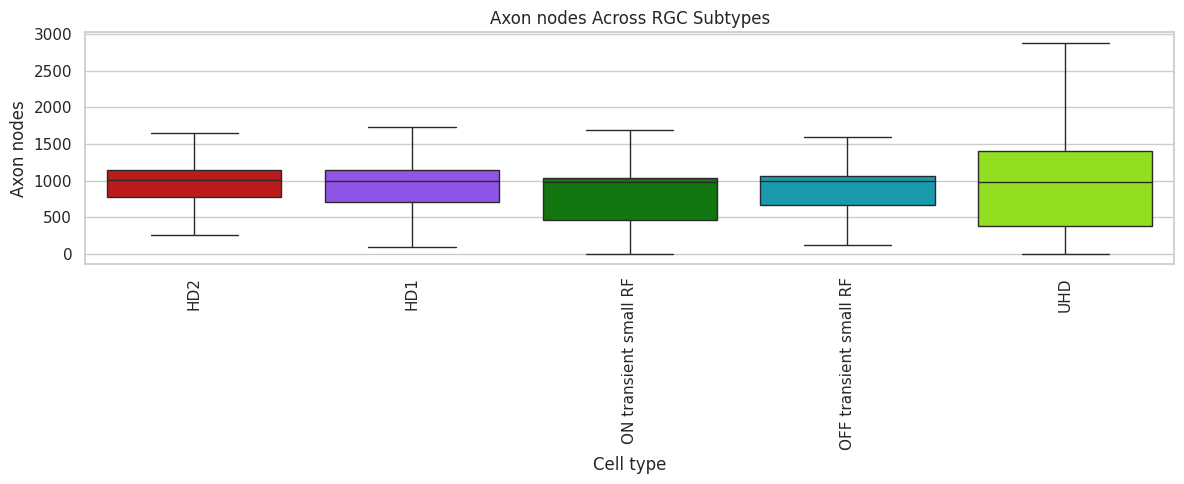

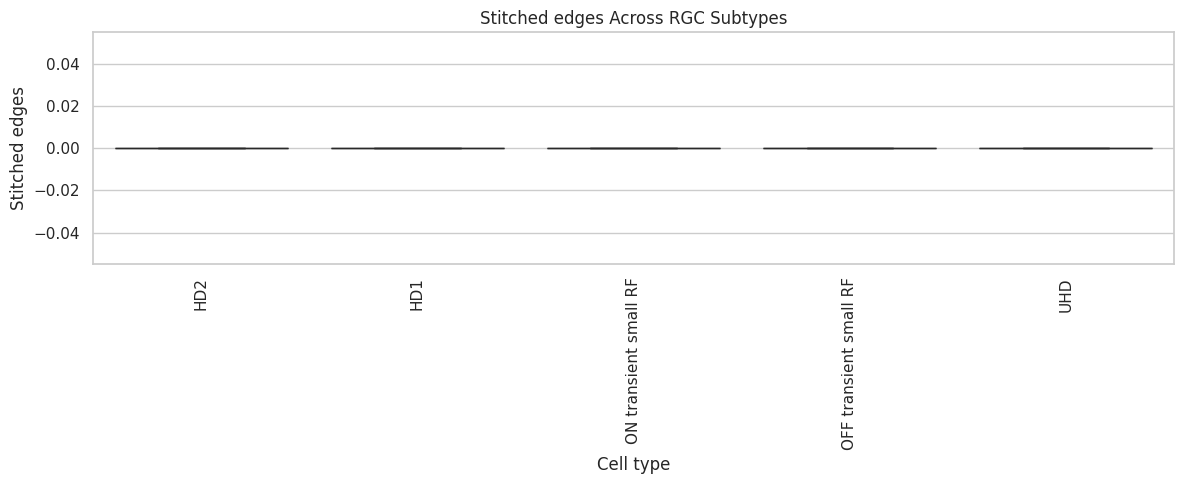

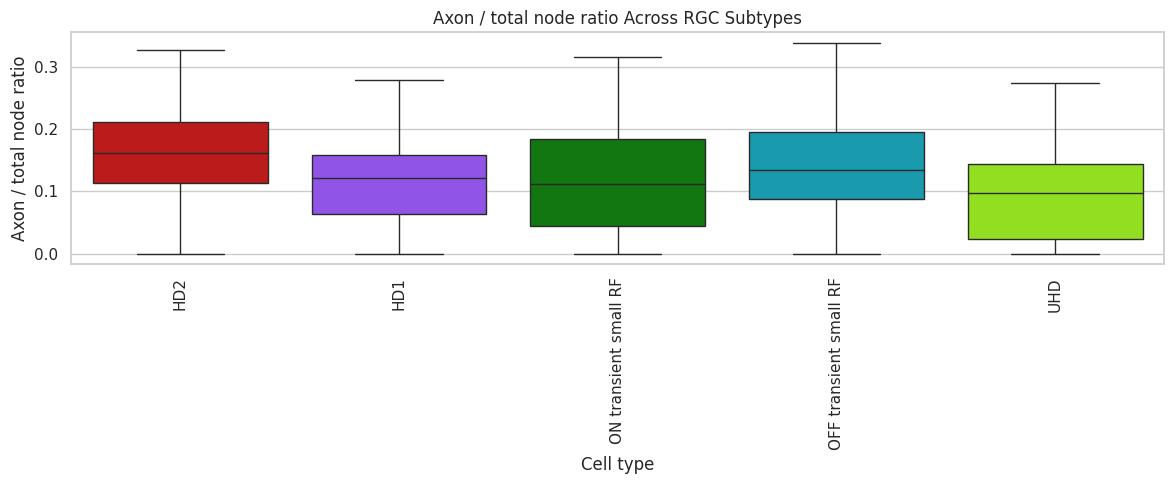

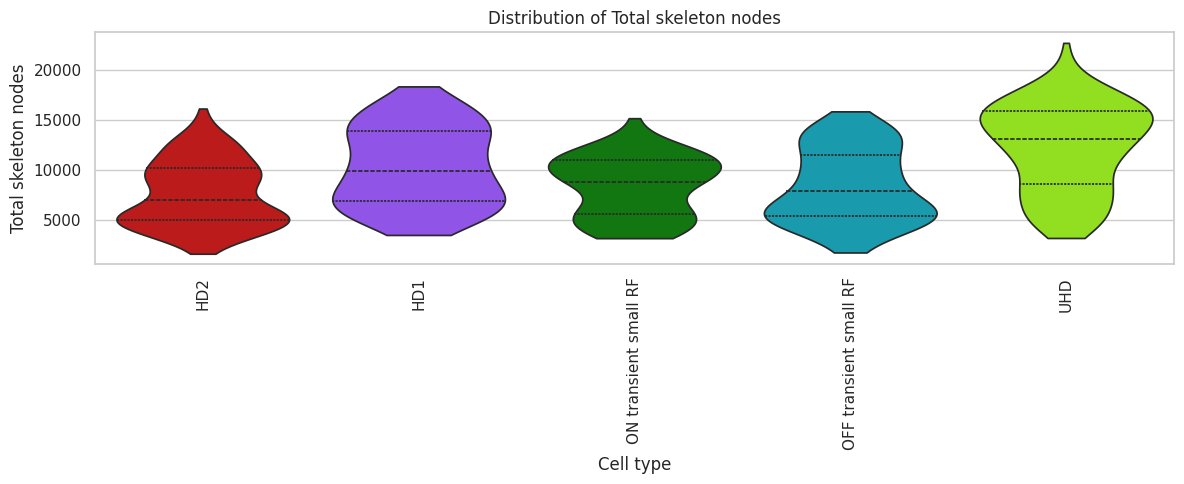

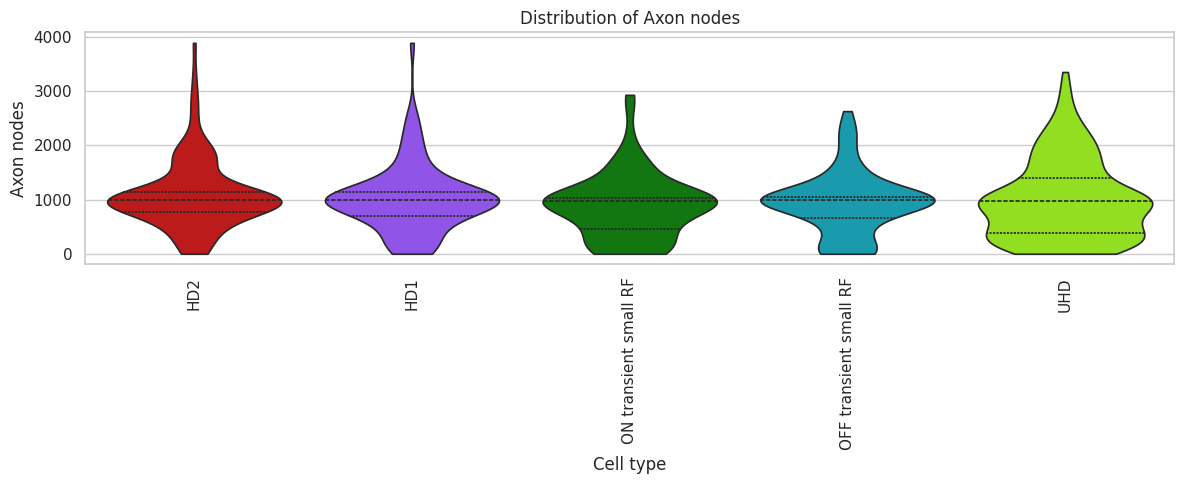

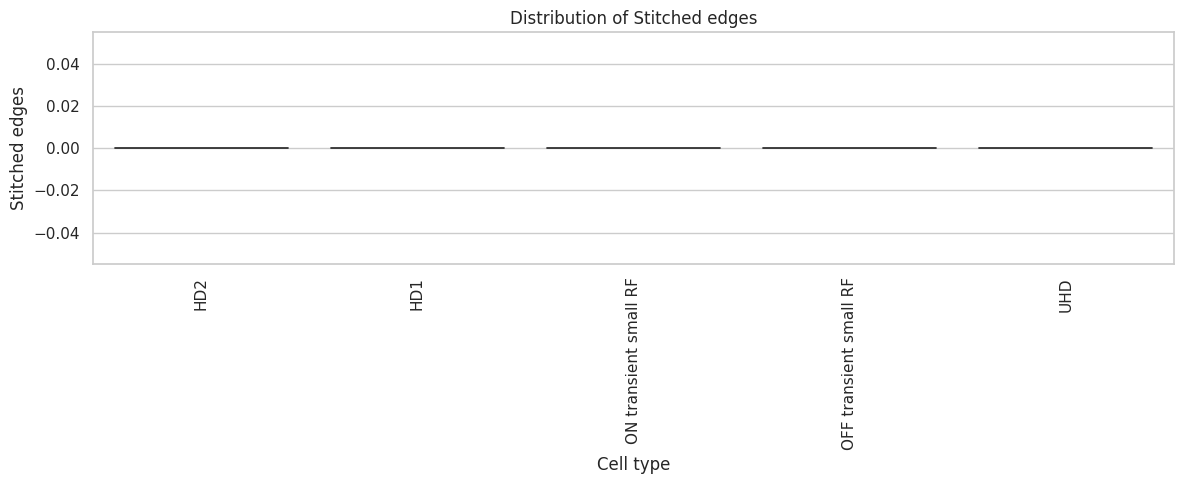

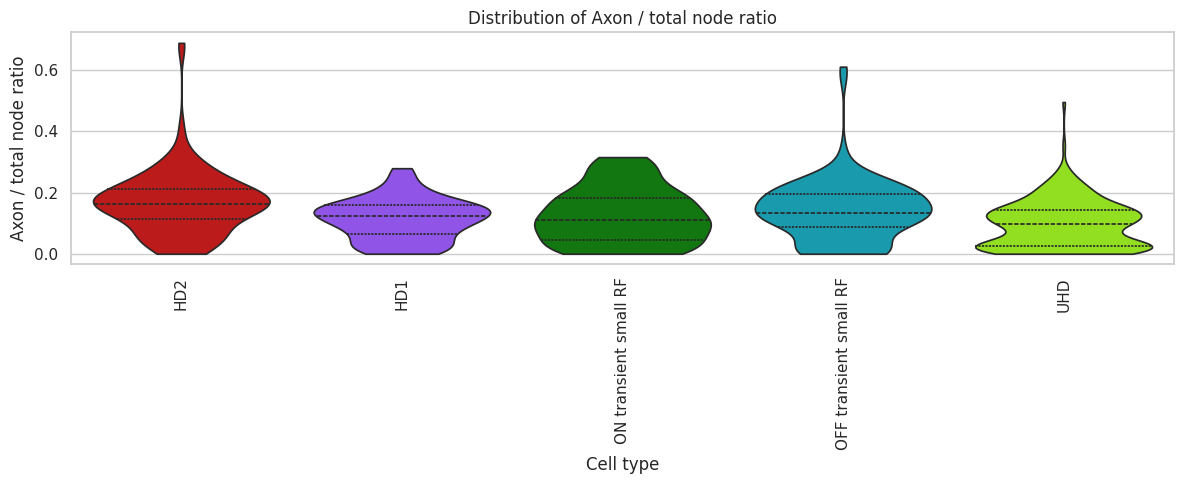


Cell type summary:


,n_cells,n_nodes,n_axon_nodes,n_stitched_edges,n_axon_nodes_ratio
celltype_final,,,,,
HD2,132,7598.95,1086.39,0.0,0.17
HD1,92,10371.47,1015.10,0.0,0.11
ON transient small RF,75,8346.43,876.95,0.0,0.13
OFF transient small RF,111,8392.56,933.57,0.0,0.14
UHD,221,12315.38,988.56,0.0,0.10


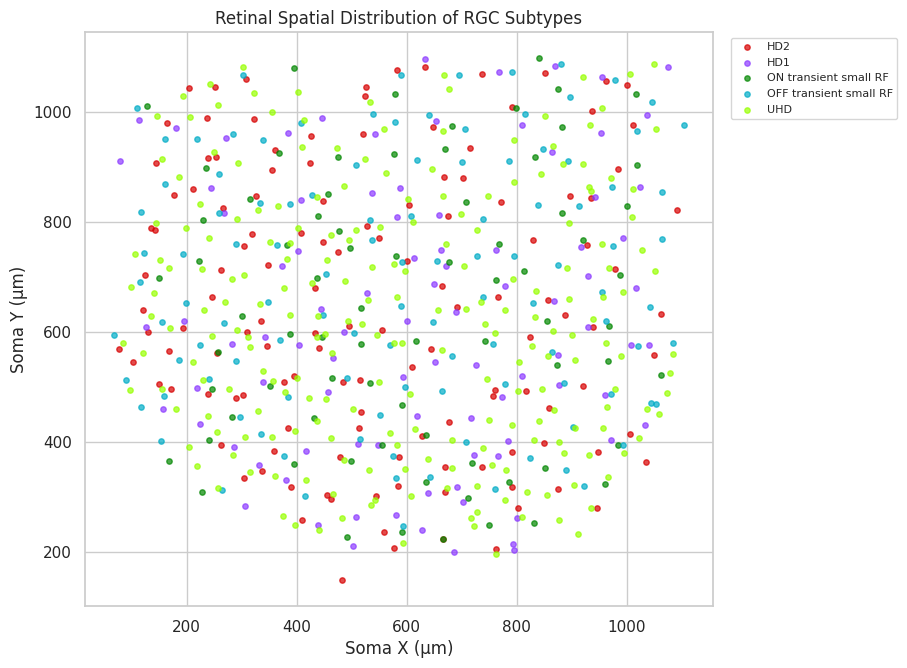

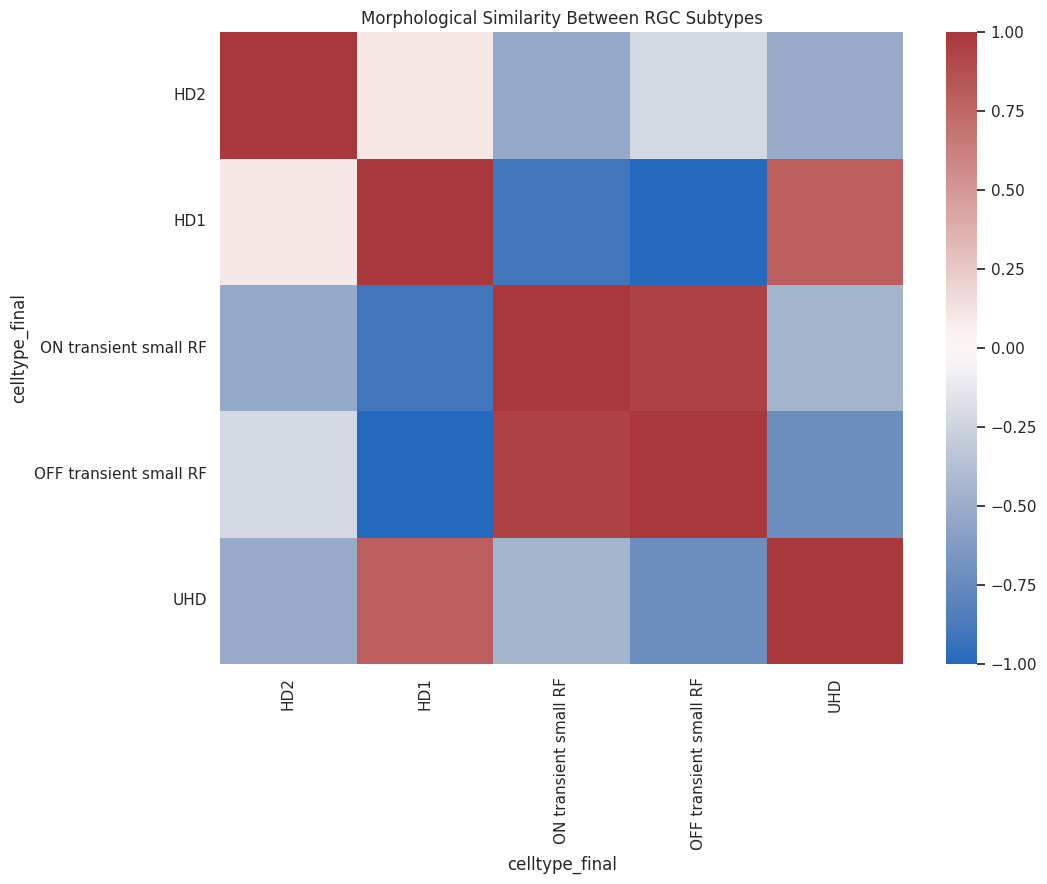


All comparisons completed!
Plots and tables saved in: RGC_celltype_comparisons


In [17]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc

from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# ============================================================
# SETTINGS
# ============================================================


output_dir = "RGC_celltype_comparisons"
os.makedirs(output_dir, exist_ok=True)

# Number of neighbours for mixing analysis
k = 15

# ============================================================
# PREPARE DATA
# ============================================================

df = cell_meta[
    cell_meta['celltype_final'].isin(selected_celltypes)
].copy()

if df.empty:
    raise ValueError("No cells found for the selected cell types.")

celltypes = [
    ct for ct in selected_celltypes
    if ct in df['celltype_final'].unique()
]

print(f"Number of cell types: {len(celltypes)}")
print(f"Number of cells: {len(df)}")

# Consistent colours
colors = cc.glasbey[:len(celltypes)]
color_dict = dict(zip(celltypes, colors))

sns.set_theme(style="whitegrid", context="notebook")

# ============================================================
# 1. NUMBER OF CELLS PER SUBTYPE
# ============================================================

counts = (
    df['celltype_final']
    .value_counts()
    .reindex(celltypes)
)

fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    x=counts.index,
    y=counts.values,
    hue=counts.index,
    palette=color_dict,
    legend=False,
    ax=ax
)

ax.set_ylabel("Number of cells")
ax.set_xlabel("Cell type")
ax.set_title("Number of Cells per RGC Subtype")
ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.savefig(f"{output_dir}/01_cell_counts.png", dpi=300)
plt.show()


# ============================================================
# 2. MORPHOLOGICAL FEATURE COMPARISONS
# ============================================================

# Only include features available in metadata
candidate_features = {
    'n_nodes': 'Total skeleton nodes',
    'n_axon_nodes': 'Axon nodes',
    'n_stitched_edges': 'Stitched edges',
    'n_axon_nodes_ratio': 'Axon / total node ratio',
    'n_dendrite_nodes': 'Dendritic nodes',
    'dendritic_length': 'Dendritic length',
    'axon_length': 'Axon length',
    'dendritic_field_area': 'Dendritic field area',
    'dendritic_field_diameter': 'Dendritic field diameter',
}

# Calculate axon-to-total-node ratio
if {'n_axon_nodes', 'n_nodes'}.issubset(df.columns):
    df['n_axon_nodes_ratio'] = (
        df['n_axon_nodes'] / df['n_nodes'].replace(0, np.nan)
    )

available_features = {
    col: label
    for col, label in candidate_features.items()
    if col in df.columns
    and pd.api.types.is_numeric_dtype(df[col])
}

print("\nMorphological features being compared:")
print(list(available_features.keys()))

for feature, label in available_features.items():

    fig, ax = plt.subplots(figsize=(12, 5))

    sns.boxplot(
        data=df,
        x='celltype_final',
        y=feature,
        order=celltypes,
        hue='celltype_final',
        palette=color_dict,
        legend=False,
        showfliers=False,
        ax=ax
    )

    ax.set_title(f"{label} Across RGC Subtypes")
    ax.set_xlabel("Cell type")
    ax.set_ylabel(label)
    ax.tick_params(axis='x', rotation=90)

    plt.tight_layout()
    plt.savefig(
        f"{output_dir}/02_{feature}.png",
        dpi=300
    )
    plt.show()


# ============================================================
# 3. MORPHOLOGICAL FEATURE DISTRIBUTIONS
# ============================================================

for feature, label in available_features.items():

    fig, ax = plt.subplots(figsize=(12, 5))

    sns.violinplot(
        data=df,
        x='celltype_final',
        y=feature,
        order=celltypes,
        hue='celltype_final',
        palette=color_dict,
        legend=False,
        inner='quartile',
        cut=0,
        ax=ax
    )

    ax.set_title(f"Distribution of {label}")
    ax.set_xlabel("Cell type")
    ax.set_ylabel(label)
    ax.tick_params(axis='x', rotation=90)

    plt.tight_layout()
    plt.savefig(
        f"{output_dir}/03_violin_{feature}.png",
        dpi=300
    )
    plt.show()


# ============================================================
# 4. SUMMARY STATISTICS
# ============================================================

summary = (
    df.groupby('celltype_final')
    .agg(
        n_cells=('cell_id', 'count'),
        **{
            feature: (feature, 'mean')
            for feature in available_features
        }
    )
    .reindex(celltypes)
)

print("\nCell type summary:")
display(summary.round(2))

summary.to_csv(f"{output_dir}/04_summary_statistics.csv")


# ============================================================
# 5. SOMA SPATIAL DISTRIBUTION
# ============================================================

spatial_cols = ['soma_x_um', 'soma_y_um']

if set(spatial_cols).issubset(df.columns):

    spatial_df = df.dropna(subset=spatial_cols)

    fig, ax = plt.subplots(figsize=(9, 8))

    for ct in celltypes:
        group = spatial_df[
            spatial_df['celltype_final'] == ct
        ]

        ax.scatter(
            group['soma_x_um'],
            group['soma_y_um'],
            color=color_dict[ct],
            label=ct,
            s=15,
            alpha=0.7
        )

    ax.set_xlabel("Soma X (µm)")
    ax.set_ylabel("Soma Y (µm)")
    ax.set_title("Retinal Spatial Distribution of RGC Subtypes")
    ax.set_aspect('equal')
    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        fontsize=8
    )

    plt.tight_layout()
    plt.savefig(f"{output_dir}/05_soma_distribution.png", dpi=300)
    plt.show()


# ============================================================
# 6. t-SNE EMBEDDING COMPARISON
# ============================================================

if 'latent' in df.columns:

    X = np.stack(df['latent'].values).astype(np.float32)

    perplexity = min(30, max(2, (len(X) - 1) // 3))

    tsne = TSNE(
        n_components=2,
        perplexity=perplexity,
        random_state=42,
        init='random',
        learning_rate=200.0
    )

    X_tsne = tsne.fit_transform(X)

    df['TSNE1'] = X_tsne[:, 0]
    df['TSNE2'] = X_tsne[:, 1]

    fig, ax = plt.subplots(figsize=(10, 8))

    for ct in celltypes:
        group = df[df['celltype_final'] == ct]

        ax.scatter(
            group['TSNE1'],
            group['TSNE2'],
            color=color_dict[ct],
            label=ct,
            s=15,
            alpha=0.75
        )

    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.set_title("RGC Subtype Separation in Latent Space")

    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        fontsize=8
    )

    plt.tight_layout()
    plt.savefig(f"{output_dir}/06_tsne.png", dpi=300)
    plt.show()


# ============================================================
# 7. NEAREST-NEIGHBOUR MIXING MATRIX
# ============================================================

if 'latent' in df.columns and len(df) > k + 1:

    X = np.stack(df['latent'].values).astype(np.float32)
    labels = df['celltype_final'].values

    nn = NearestNeighbors(
        n_neighbors=k + 1,
        metric='euclidean'
    )

    nn.fit(X)
    _, indices = nn.kneighbors(X)

    neighbour_indices = indices[:, 1:]

    mixing = pd.DataFrame(
        0.0,
        index=celltypes,
        columns=celltypes
    )

    for i, ct in enumerate(labels):

        neighbour_labels = labels[neighbour_indices[i]]

        counts = pd.Series(neighbour_labels).value_counts()

        for neighbour_type, count in counts.items():
            mixing.loc[ct, neighbour_type] += count

    mixing = mixing.div(mixing.sum(axis=1), axis=0)

    fig, ax = plt.subplots(figsize=(12, 10))

    sns.heatmap(
        mixing,
        cmap='viridis',
        vmin=0,
        vmax=1,
        ax=ax
    )

    ax.set_title(
        f"Nearest-Neighbour Mixing Between RGC Subtypes (k={k})"
    )
    ax.set_xlabel("Neighbour cell type")
    ax.set_ylabel("Cell type")

    plt.tight_layout()
    plt.savefig(f"{output_dir}/07_neighbour_mixing.png", dpi=300)
    plt.show()

    mixing.to_csv(f"{output_dir}/07_neighbour_mixing.csv")


# ============================================================
# 8. MORPHOLOGICAL SIMILARITY BETWEEN CELL TYPES
# ============================================================

# Use available numeric morphological features
# Exclude ratios if their underlying features are already included
similarity_features = [
    f for f in [
        'n_nodes',
        'n_axon_nodes',
        'n_stitched_edges',
        'n_dendrite_nodes',
        'dendritic_length',
        'axon_length',
        'dendritic_field_area',
        'dendritic_field_diameter'
    ]
    if f in df.columns
]

if len(similarity_features) >= 2:

    type_means = (
        df.groupby('celltype_final')[similarity_features]
        .mean()
        .reindex(celltypes)
    )

    # Remove features with no variation or missing means
    type_means = type_means.dropna(axis=1)

    if type_means.shape[1] >= 2:

        X_morph = StandardScaler().fit_transform(type_means)

        similarity = pd.DataFrame(
            cosine_similarity(X_morph),
            index=type_means.index,
            columns=type_means.index
        )

        fig, ax = plt.subplots(figsize=(11, 9))

        sns.heatmap(
            similarity,
            cmap='vlag',
            center=0,
            vmin=-1,
            vmax=1,
            ax=ax
        )

        ax.set_title(
            "Morphological Similarity Between RGC Subtypes"
        )

        plt.tight_layout()
        plt.savefig(
            f"{output_dir}/08_morphological_similarity.png",
            dpi=300
        )
        plt.show()

        similarity.to_csv(
            f"{output_dir}/08_morphological_similarity.csv"
        )


print("\n===================================")
print("All comparisons completed!")
print(f"Plots and tables saved in: {output_dir}")
print("===================================")


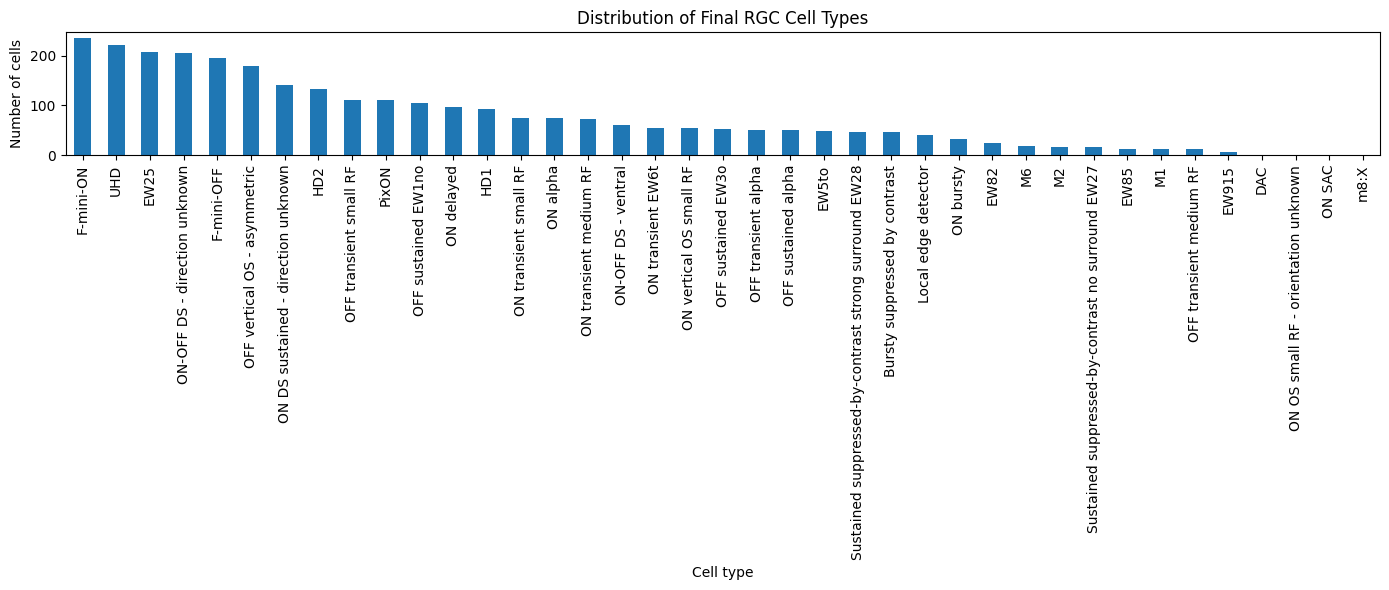

In [8]:
celltype_counts = cell_meta['celltype_final'].value_counts()

plt.figure(figsize=(14, 6))
celltype_counts.plot(kind='bar')

plt.xlabel('Cell type')
plt.ylabel('Number of cells')
plt.title('Distribution of Final RGC Cell Types')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
eval_results_val.head()

,Unnamed: 0,n_train,n_val,5nn_bal_acc,5nn_bal_acc_ci_lo,5nn_bal_acc_ci_hi,5nn_acc,5nn_bal_acc_consensus,5nn_bal_acc_strong,P@10,linear_bal_acc,n_loo,5nn_loo_bal_acc,5nn_loo_bal_acc_consensus,SC,DBI,kmeans_ARI,E_top10
0,depth-profile baseline,2330.0,291.0,0.814421,0.781271,0.845934,0.931271,0.810316,0.904348,0.772583,0.886561,2621.0,0.860469,0.855011,0.315130,1.555818,0.780500,0.959595
1,GraphDINO,2330.0,291.0,0.489935,0.441519,0.542764,0.659794,0.500624,0.653541,0.412779,0.530313,2621.0,0.496678,0.503338,-0.016067,3.909837,0.340746,0.999426
2,GICLMorph,2330.0,291.0,0.830648,0.794002,0.865947,0.931271,0.827390,0.932494,0.726405,0.847611,2621.0,0.804976,0.806338,0.239992,1.880029,0.577683,0.997271


#### Projections

In [10]:
uhd_cells = cell_meta[cell_meta['celltype_final'] == "F-mini-OFF"]

In [11]:
uhd_cells

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um
7,720575940537434291,805.556350,627.248801,-12.997574,10211,8080,2131,0,RGC,True,True,F-mini-OFF,True,both_strong,805.556,627.249,-12.9976
8,720575940537466547,429.913720,322.659286,-16.144982,13866,12954,912,0,RGC,True,True,F-mini-OFF,True,both_strong,429.914,322.659,-16.1450
22,720575940540777592,503.411339,764.647493,-15.715467,13959,12806,1153,0,RGC,True,True,F-mini-OFF,True,both_strong,503.411,764.648,-15.7155
57,720575940546274547,954.054109,865.908794,-13.935967,15179,15016,163,0,RGC,True,True,F-mini-OFF,True,both_strong,954.054,865.909,-13.9360
65,720575940546570581,728.984831,1076.049335,-14.303068,16688,16445,243,0,RGC,True,True,F-mini-OFF,True,both_strong,728.985,1076.050,-14.3031
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3609,720575940583868539,860.890950,832.557033,-15.346392,16115,16115,0,0,RGC,True,True,F-mini-OFF,True,both_strong,860.891,832.557,-15.3464
3617,720575940584466299,684.893447,984.194583,-13.956820,12993,12842,151,0,RGC,True,True,F-mini-OFF,True,classifier,684.893,984.195,-13.9568
3632,720575940585183443,738.780425,425.420083,-14.063861,16147,14571,1576,0,RGC,True,True,F-mini-OFF,True,both_strong,738.780,425.420,-14.0639
3634,720575940585259030,828.992319,413.639310,-10.541056,12027,10646,1381,0,RGC,True,True,F-mini-OFF,True,both_strong,828.992,413.639,-10.5411


In [12]:
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "preprocessing" else Path.cwd()
data_path = ROOT_DIR / "data" / "raw" / "data"

skeleton_dir = data_path / "skeletons" / "720575940585183443"

features = np.load(skeleton_dir / "features.npy")

with open(skeleton_dir / "neighbors.pkl", "rb") as f:
    neighbors = pickle.load(f)

projections = np.load(skeleton_dir / "projections.npy")

shape: (7, 224, 224)
dtype: uint8


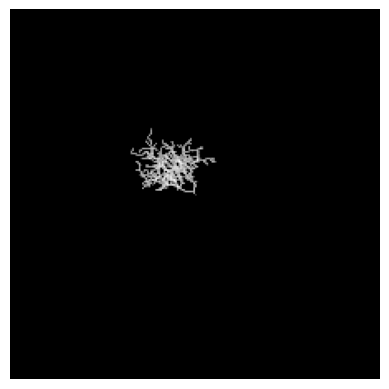

In [13]:
print("shape:", projections.shape)
print("dtype:", projections.dtype)

plt.imshow(projections[6], cmap="gray")
plt.axis("off")
plt.show()

In [14]:
feature_cols = [
    "arbor_area_xy",
    "arbor_depth_z",
    "max_path_length_from_soma",
    "n_primary_branches",
    "mean_distance_from_soma",
    "max_distance_from_soma",
    "max_diameter_3d",
    "n_terminal_tips",
    "primary_branch_alignment",
    "primary_branch_angle_mean_deg",
    "primary_branch_angle_std_deg",
]

In [15]:
cell_1 = skeletons['720575940537162675']
print(len(cell_1.neighbors), cell_1.features.shape)

8096 (8096, 3)


#### Plot using skel

In [16]:
# fig, ax = sk.plot2d(skel)

## Data Analysis

In [17]:
cell_meta.head()

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision,soma_x_um,soma_y_um,soma_z_um
0,720575940537162675,623.088321,271.935098,-21.628196,9054,8096,958,0,RGC,True,True,NaN,False,NaN,623.088,271.935,-21.6282
1,720575940537274291,483.576538,891.599123,-14.109626,5112,3943,1169,0,RGC,True,True,ON alpha,True,both_strong,483.577,891.599,-14.1096
2,720575940537284275,477.293864,607.582202,-18.812998,6950,6137,813,0,RGC,True,True,Sustained suppressed-by-contrast strong surrou...,True,both_weak,477.294,607.582,-18.8130
3,720575940537313971,778.958349,719.019178,-14.450323,8642,7627,1015,0,RGC,True,True,ON delayed,True,both_strong,778.958,719.019,-14.4503
4,720575940537343155,283.318443,409.646856,-16.305329,9935,8934,1001,0,RGC,True,True,OFF vertical OS - asymmetric,True,both_strong,283.318,409.647,-16.3053


In [18]:
cell_meta.columns

Index(['cell_id', 'soma_x', 'soma_y', 'soma_z', 'n_nodes_raw', 'n_nodes',
       'n_axon_nodes', 'n_stitched_edges', 'cellclass_final',
       'valid_cellclass_final', 'valid_status', 'celltype_final',
       'valid_celltype_final', 'celltype_final_decision', 'soma_x_um',
       'soma_y_um', 'soma_z_um'],
      dtype='object')

In [19]:
cell_meta = cell_meta.drop(columns=['soma_x_um', 'soma_y_um', 'soma_z_um'])

#### Number of nodes based on cell type

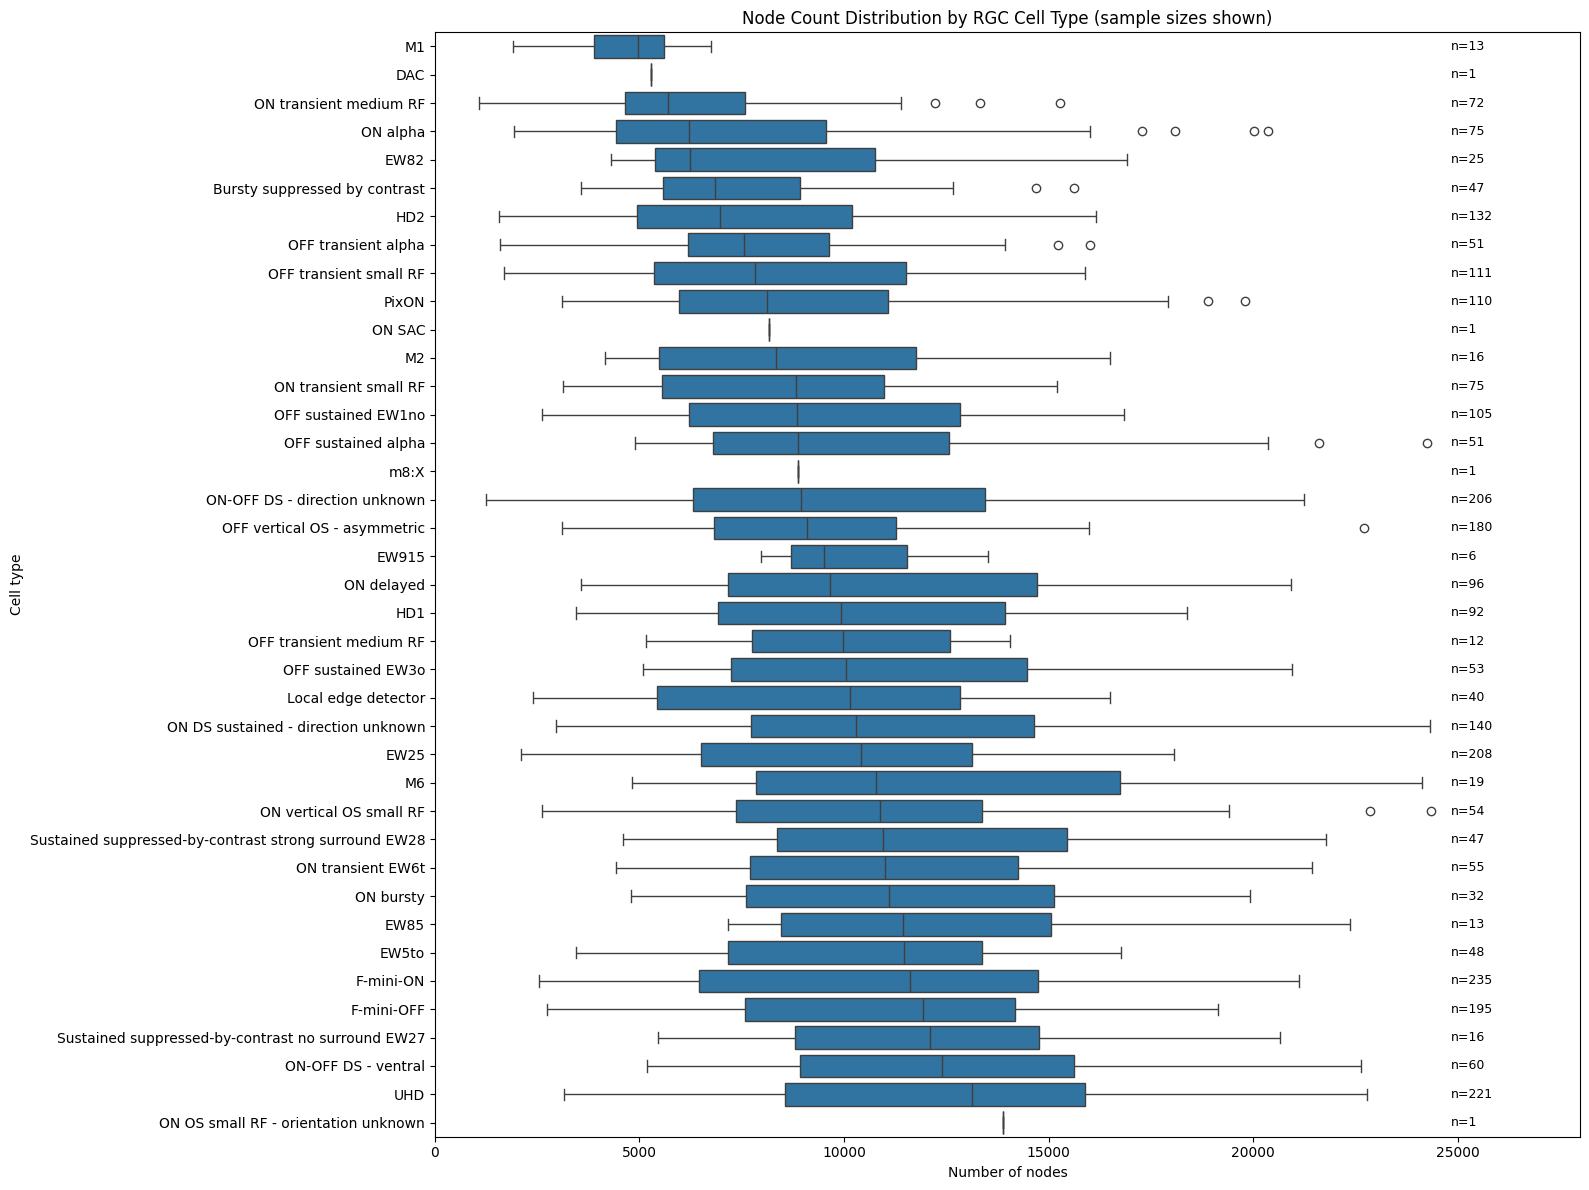

In [20]:
df = cell_meta.dropna(subset=['celltype_final', 'n_nodes']).copy()

type_order = (
    df.groupby('celltype_final')['n_nodes']
      .median()
      .sort_values()
      .index
)

sample_counts = df['celltype_final'].value_counts()

fig, ax = plt.subplots(figsize=(16, 12))

sns.boxplot(
    data=df,
    x='n_nodes',
    y='celltype_final',
    order=type_order,
    ax=ax
)

x_max = df['n_nodes'].max()

for y, cell_type in enumerate(type_order):
    n = sample_counts[cell_type]
    ax.text(
        x_max * 1.02,
        y,
        f'n={n}',
        va='center',
        fontsize=9
    )

ax.set_xlim(0, x_max * 1.15)
ax.set_xlabel('Number of nodes')
ax.set_ylabel('Cell type')
ax.set_title('Node Count Distribution by RGC Cell Type (sample sizes shown)')

plt.tight_layout()
plt.show()

Number of skeletons: 3690
Total number of nodes plotted: 36,787,919


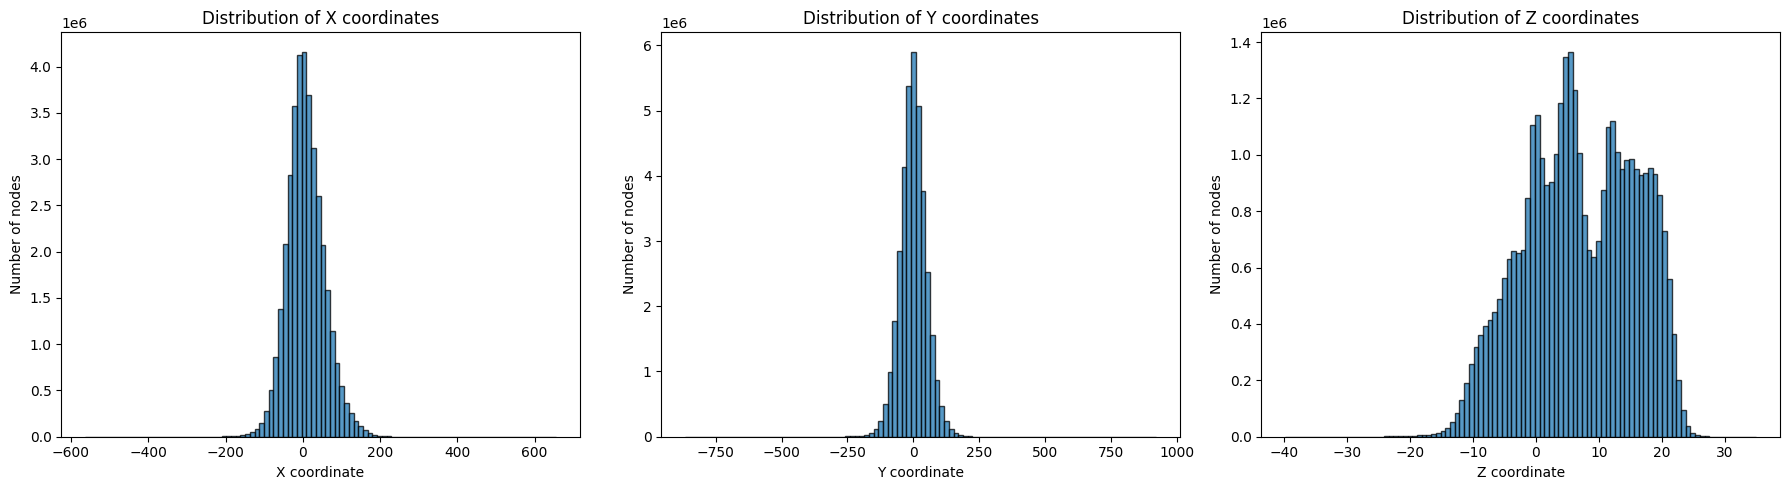

In [21]:
all_coords = []

for skeleton_id, skeleton in skeletons.items():
    coords = np.asarray(skeleton.features)

    if coords.ndim == 2 and coords.shape[1] == 3:
        # Exclude invalid coordinates
        coords = coords[np.all(np.isfinite(coords), axis=1)]
        if len(coords) > 0:
            all_coords.append(coords)

all_coords = np.vstack(all_coords)

x = all_coords[:, 0]
y = all_coords[:, 1]
z = all_coords[:, 2]

print(f"Number of skeletons: {len(skeletons)}")
print(f"Total number of nodes plotted: {len(all_coords):,}")

# Plot three distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(x, bins=100, edgecolor="black", alpha=0.75)
axes[0].set_title("Distribution of X coordinates")
axes[0].set_xlabel("X coordinate")
axes[0].set_ylabel("Number of nodes")

axes[1].hist(y, bins=100, edgecolor="black", alpha=0.75)
axes[1].set_title("Distribution of Y coordinates")
axes[1].set_xlabel("Y coordinate")
axes[1].set_ylabel("Number of nodes")

axes[2].hist(z, bins=100, edgecolor="black", alpha=0.75)
axes[2].set_title("Distribution of Z coordinates")
axes[2].set_xlabel("Z coordinate")
axes[2].set_ylabel("Number of nodes")

plt.tight_layout()
plt.show()


Cells with soma_x: 3,690
Cells with soma_y: 3,690
Cells with soma_z: 3,690


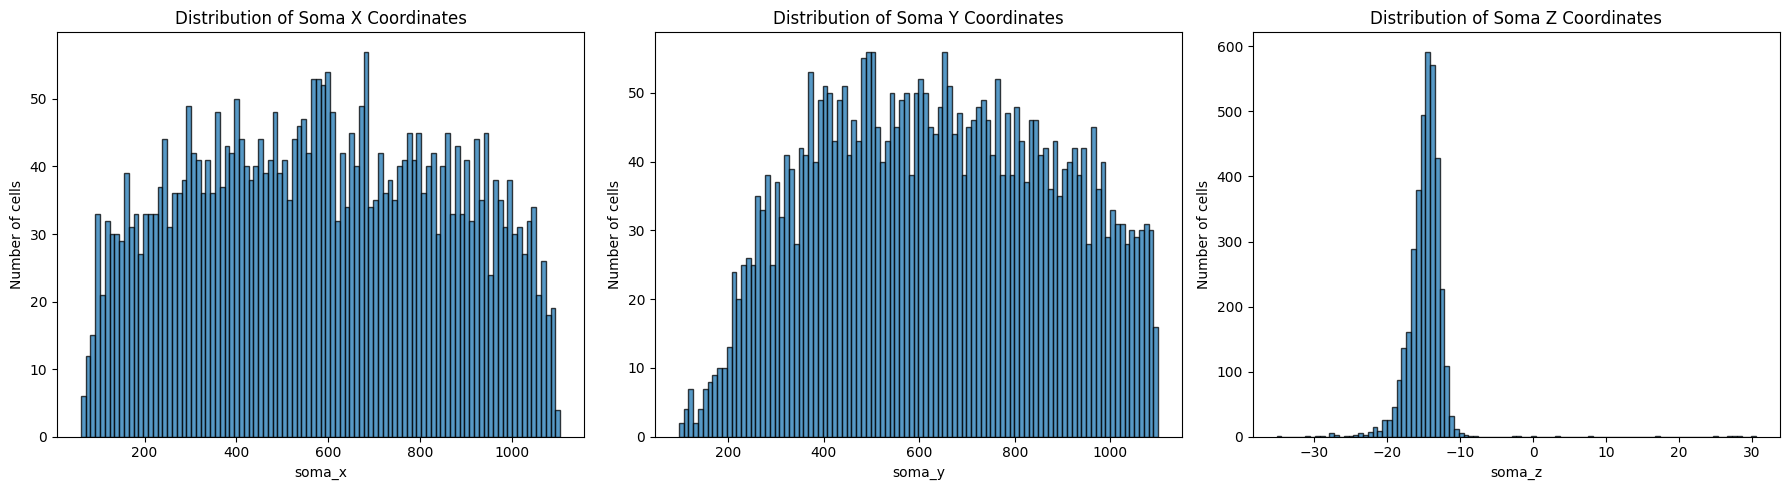

In [22]:
soma_x = cell_meta["soma_x"].dropna().to_numpy()
soma_y = cell_meta["soma_y"].dropna().to_numpy()
soma_z = cell_meta["soma_z"].dropna().to_numpy()

print(f"Cells with soma_x: {len(soma_x):,}")
print(f"Cells with soma_y: {len(soma_y):,}")
print(f"Cells with soma_z: {len(soma_z):,}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(soma_x, bins=100, edgecolor="black", alpha=0.75)
axes[0].set_title("Distribution of Soma X Coordinates")
axes[0].set_xlabel("soma_x")
axes[0].set_ylabel("Number of cells")

axes[1].hist(soma_y, bins=100, edgecolor="black", alpha=0.75)
axes[1].set_title("Distribution of Soma Y Coordinates")
axes[1].set_xlabel("soma_y")
axes[1].set_ylabel("Number of cells")

axes[2].hist(soma_z, bins=100, edgecolor="black", alpha=0.75)
axes[2].set_title("Distribution of Soma Z Coordinates")
axes[2].set_xlabel("soma_z")
axes[2].set_ylabel("Number of cells")

plt.tight_layout()
plt.show()

In [18]:
cell_meta[cell_meta['cell_id'] == 720575940537162675]

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,valid_status,celltype_final,valid_celltype_final,celltype_final_decision


## Feature Extraction

In [ ]:
def calculate_cell_morphology(skeleton):
    """
    Calculate cell-level morphology features from a skeleton graph.

    Assumptions
    -----------
    - skeleton.features contains node coordinates with shape (N, 3).
    - skeleton.neighbors maps node indices to neighboring node indices.
    - Node 0 is the soma.
    - Coordinates use a consistent spatial unit.
    """

    coords = np.asarray(skeleton.features, dtype=float)
    neighbors = skeleton.neighbors

    n_nodes = len(coords)

    # Return NaNs for empty skeletons.
    if n_nodes == 0:
        return {}

    soma_idx = 0
    soma = coords[soma_idx]

    # --------------------------------------------------
    # 1. Straight-line distances from soma
    # --------------------------------------------------

    distances_from_soma = np.linalg.norm(coords - soma, axis=1)

    mean_distance_from_soma = np.mean(distances_from_soma)
    max_distance_from_soma = np.max(distances_from_soma)

    # --------------------------------------------------
    # 2. Build weighted adjacency matrix
    # --------------------------------------------------

    rows = []
    cols = []
    weights = []

    for i, nbrs in neighbors.items():
        i = int(i)

        for j in nbrs:
            j = int(j)

            if i < 0 or i >= n_nodes or j < 0 or j >= n_nodes:
                continue

            # Add each undirected edge once.
            if i < j:
                edge_length = np.linalg.norm(coords[i] - coords[j])

                rows.extend([i, j])
                cols.extend([j, i])
                weights.extend([edge_length, edge_length])

    adjacency = csr_matrix(
        (weights, (rows, cols)),
        shape=(n_nodes, n_nodes)
    )

    # --------------------------------------------------
    # 3. Longest shortest-path distance from soma
    # --------------------------------------------------

    graph_distances = shortest_path(
        adjacency,
        directed=False,
        indices=soma_idx,
        unweighted=False
    )

    reachable = np.isfinite(graph_distances)

    if np.any(reachable):
        max_path_length_from_soma = np.max(
            graph_distances[reachable]
        )
    else:
        max_path_length_from_soma = np.nan

    # --------------------------------------------------
    # 4. Number of primary branches leaving the soma
    # --------------------------------------------------

    n_primary_branches = len(neighbors.get(soma_idx, set()))

    # --------------------------------------------------
    # 5. Number of terminal tips
    # --------------------------------------------------

    degrees = np.zeros(n_nodes, dtype=int)

    for i, nbrs in neighbors.items():
        i = int(i)

        if 0 <= i < n_nodes:
            degrees[i] = len(nbrs)

    n_terminal_tips = np.sum(
        (degrees == 1) &
        (np.arange(n_nodes) != soma_idx)
    )

    # --------------------------------------------------
    # 6. XY-projected arbor area
    # --------------------------------------------------

    # removes the z plane to get the view of the arbor from above.
    
    xy = coords[:, :2]
    unique_xy = np.unique(xy, axis=0)

    if len(unique_xy) >= 3:
        try:
            arbor_area_xy = ConvexHull(unique_xy).volume
        except Exception:
            arbor_area_xy = np.nan
    else:
        arbor_area_xy = 0.0

    # --------------------------------------------------
    # 7. Z depth
    # --------------------------------------------------

    arbor_depth_z = np.ptp(coords[:, 2])

    # --------------------------------------------------
    # 8. Maximum 3D diameter
    # --------------------------------------------------

    # Use the convex hull vertices where possible, because
    # the maximum pairwise distance occurs on the convex hull.
    unique_xyz = np.unique(coords, axis=0)

    if len(unique_xyz) < 2:
        max_diameter_3d = 0.0
    else:
        try:
            hull = ConvexHull(unique_xyz)
            diameter_points = unique_xyz[hull.vertices]
        except Exception:
            diameter_points = unique_xyz

        # Chunk the computation to avoid allocating an
        # excessively large pairwise distance matrix.
        max_diameter_3d = 0.0
        chunk_size = 500

        for start in range(0, len(diameter_points), chunk_size):
            chunk = diameter_points[start:start + chunk_size]

            pairwise_distances = distance.cdist(
                chunk,
                diameter_points
            )

            max_diameter_3d = max(
                max_diameter_3d,
                np.max(pairwise_distances)
            )

    # --------------------------------------------------
    # 9. Primary branch directions and angles
    # --------------------------------------------------

    primary_branch_angles = []
    primary_branch_vectors = []

    soma_neighbors = sorted(
        int(i) for i in neighbors.get(soma_idx, set())
    )

    for node_idx in soma_neighbors:
        vector = coords[node_idx] - soma

        norm = np.linalg.norm(vector)

        if norm == 0:
            continue

        unit_vector = vector / norm
        primary_branch_vectors.append(unit_vector)

        # Azimuthal angle in the XY plane, relative to +X.
        # Range: [-180, 180] degrees.
        angle_deg = np.degrees(
            np.arctan2(vector[1], vector[0])
        )

        primary_branch_angles.append(angle_deg)

    primary_branch_angles = np.asarray(
        primary_branch_angles,
        dtype=float
    )

    if len(primary_branch_angles) > 0:
        primary_branch_angle_mean_deg = np.mean(
            primary_branch_angles
        )
        primary_branch_angle_std_deg = np.std(
            primary_branch_angles
        )
    else:
        primary_branch_angle_mean_deg = np.nan
        primary_branch_angle_std_deg = np.nan

    # --------------------------------------------------
    # 10. Alignment of primary branches
    # --------------------------------------------------

    # A branch direction and its reverse are treated as
    # equivalent: parallel branches should score highly
    # whether they point in the same or opposite directions.
    #
    # Alignment = mean of |dot product| over all branch pairs.
    #
    # 1 = all branch directions are parallel or antiparallel.
    # 0 = branch directions are mutually orthogonal on average.

    vectors = np.asarray(primary_branch_vectors)

    if len(vectors) >= 2:
        dot_products = vectors @ vectors.T

        upper_triangle = np.triu_indices(
            len(vectors),
            k=1
        )

        pairwise_alignment = np.abs(
            dot_products[upper_triangle]
        )

        primary_branch_alignment = np.mean(
            pairwise_alignment
        )
    elif len(vectors) == 1:
        primary_branch_alignment = 1.0
    else:
        primary_branch_alignment = np.nan

    # --------------------------------------------------
    # Return cell-level features
    # --------------------------------------------------

    return {
        "arbor_area_xy": arbor_area_xy,
        "arbor_depth_z": arbor_depth_z,
        "max_path_length_from_soma": max_path_length_from_soma,
        "n_primary_branches": n_primary_branches,
        "mean_distance_from_soma": mean_distance_from_soma,
        "max_distance_from_soma": max_distance_from_soma,
        "max_diameter_3d": max_diameter_3d,
        "n_terminal_tips": int(n_terminal_tips),
        "primary_branch_alignment": primary_branch_alignment,
        "primary_branch_angles_deg": primary_branch_angles.tolist(),
        "primary_branch_angle_mean_deg": primary_branch_angle_mean_deg,
        "primary_branch_angle_std_deg": primary_branch_angle_std_deg,
    }

In [20]:
morphology_results = []
errors = []

for cell_id in tqdm(
    cell_meta["cell_id"],
    desc="Calculating morphology features",
    unit="cell"
):
    # Use the original ID without converting its type.
    skeleton = skeletons.get(cell_id)

    if skeleton is None:
        morphology_results.append({
            "cell_id": cell_id,
            "morphology_calculation_failed": True
        })
        errors.append((cell_id, "Skeleton not found"))
        continue

    try:
        features = calculate_cell_morphology(skeleton)

        morphology_results.append({
            "cell_id": cell_id,
            "morphology_calculation_failed": False,
            **features
        })

    except Exception as e:
        morphology_results.append({
            "cell_id": cell_id,
            "morphology_calculation_failed": True
        })
        errors.append((cell_id, repr(e)))

morphology_df = pd.DataFrame(morphology_results)

# Merge without changing either column's data type.
cell_meta = cell_meta.merge(
    morphology_df,
    on="cell_id",
    how="left",
    validate="one_to_one"
)

print(f"Successfully processed: {(~cell_meta['morphology_calculation_failed']).sum():,}")
print(f"Failed: {cell_meta['morphology_calculation_failed'].sum():,}")

if errors:
    print("\nFirst 10 errors:")
    for cell_id, error in errors[:10]:
        print(f"Cell {cell_id}: {error}")

Calculating morphology features:   0%|          | 0/3690 [00:00<?, ?cell/s]

Successfully processed: 3,690
Failed: 0


In [22]:
cell_meta

,cell_id,soma_x,soma_y,soma_z,n_nodes_raw,n_nodes,n_axon_nodes,n_stitched_edges,cellclass_final,valid_cellclass_final,...,max_path_length_from_soma,n_primary_branches,mean_distance_from_soma,max_distance_from_soma,max_diameter_3d,n_terminal_tips,primary_branch_alignment,primary_branch_angles_deg,primary_branch_angle_mean_deg,primary_branch_angle_std_deg
0,720575940537162675,623.088321,271.935098,-21.628196,9054,8096,958,0,RGC,True,...,136.987650,1,49.820076,101.738133,132.650184,440,1.000000,[-58.64644455174254],-58.646445,0.000000
1,720575940537274291,483.576538,891.599123,-14.109626,5112,3943,1169,0,RGC,True,...,216.423977,3,72.107144,180.587018,304.216566,243,0.326414,"[-25.099476412002744, 93.11165212477715, -136....",-22.903904,93.842809
2,720575940537284275,477.293864,607.582202,-18.812998,6950,6137,813,0,RGC,True,...,228.365823,4,57.052207,126.421438,208.916007,303,0.485539,"[154.48383986690257, 105.84507073679734, -125....",9.379788,122.426662
3,720575940537313971,778.958349,719.019178,-14.450323,8642,7627,1015,0,RGC,True,...,214.378837,3,66.014632,157.941876,260.471812,276,0.341299,"[-75.14131195097767, 165.53447059990427, 146.0...",78.800590,109.144848
4,720575940537343155,283.318443,409.646856,-16.305329,9935,8934,1001,0,RGC,True,...,311.798462,1,133.732822,231.970833,231.970833,162,1.000000,[-41.51555390681455],-41.515554,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3685,720575940589082516,271.145212,1050.133062,-13.881681,9780,9657,123,0,RGC,True,...,1051.154260,3,215.538201,867.173300,933.379445,268,0.428915,"[128.50239187481176, -55.20378645499994, -161....",-29.553026,119.958979
3686,720575940589088148,281.992055,1067.835937,-14.430131,17577,14828,2749,0,RGC,True,...,279.065567,2,68.246342,162.372889,217.082619,388,0.250957,"[-122.62157012062524, -42.694470318371806]",-82.658020,39.963550
3687,720575940589111700,851.058152,1070.755962,-14.051774,13661,11003,2658,0,RGC,True,...,172.185831,2,52.235317,117.594551,157.211159,430,0.203637,"[-112.65603936264617, 21.887104377004512]",-45.384467,67.271572
3688,720575940589184404,1036.643098,993.958841,-13.925180,16997,15377,1620,0,RGC,True,...,170.071097,4,52.169779,115.872788,163.165732,513,0.568083,"[-5.077071280044693, -74.17643737428313, 69.12...",-33.983729,73.334868


## Analysis of new features

In [ ]:
feature_cols = [
    "arbor_area_xy",
    "arbor_depth_z",
    "max_path_length_from_soma",
    "n_primary_branches",
    "mean_distance_from_soma",
    "max_distance_from_soma",
    "max_diameter_3d",
    "n_terminal_tips",
    "primary_branch_alignment",
    "primary_branch_angle_mean_deg",
    "primary_branch_angle_std_deg",
]

# Keep cells with a known cell type
plot_df = cell_meta.loc[
    cell_meta["celltype_final"].notna()
].copy()

for col in feature_cols:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

# Keep only cell types with at least 4 cells
celltype_counts = plot_df["celltype_final"].value_counts()
keep_celltypes = celltype_counts[celltype_counts >= 4].index

plot_df = plot_df[
    plot_df["celltype_final"].isin(keep_celltypes)
].copy()

print("Cells retained:", len(plot_df))
print("Cell types retained:", plot_df["celltype_final"].nunique())
print("\nSamples per cell type:")
print(plot_df["celltype_final"].value_counts().to_string())

Cells retained: 2911
Cell types retained: 35

Samples per cell type:
celltype_final
F-mini-ON                                                235
UHD                                                      221
EW25                                                     208
ON-OFF DS - direction unknown                            206
F-mini-OFF                                               195
OFF vertical OS - asymmetric                             180
ON DS sustained - direction unknown                      140
HD2                                                      132
OFF transient small RF                                   111
PixON                                                    110
OFF sustained EW1no                                      105
ON delayed                                                96
HD1                                                       92
ON transient small RF                                     75
ON alpha                                                  75
O

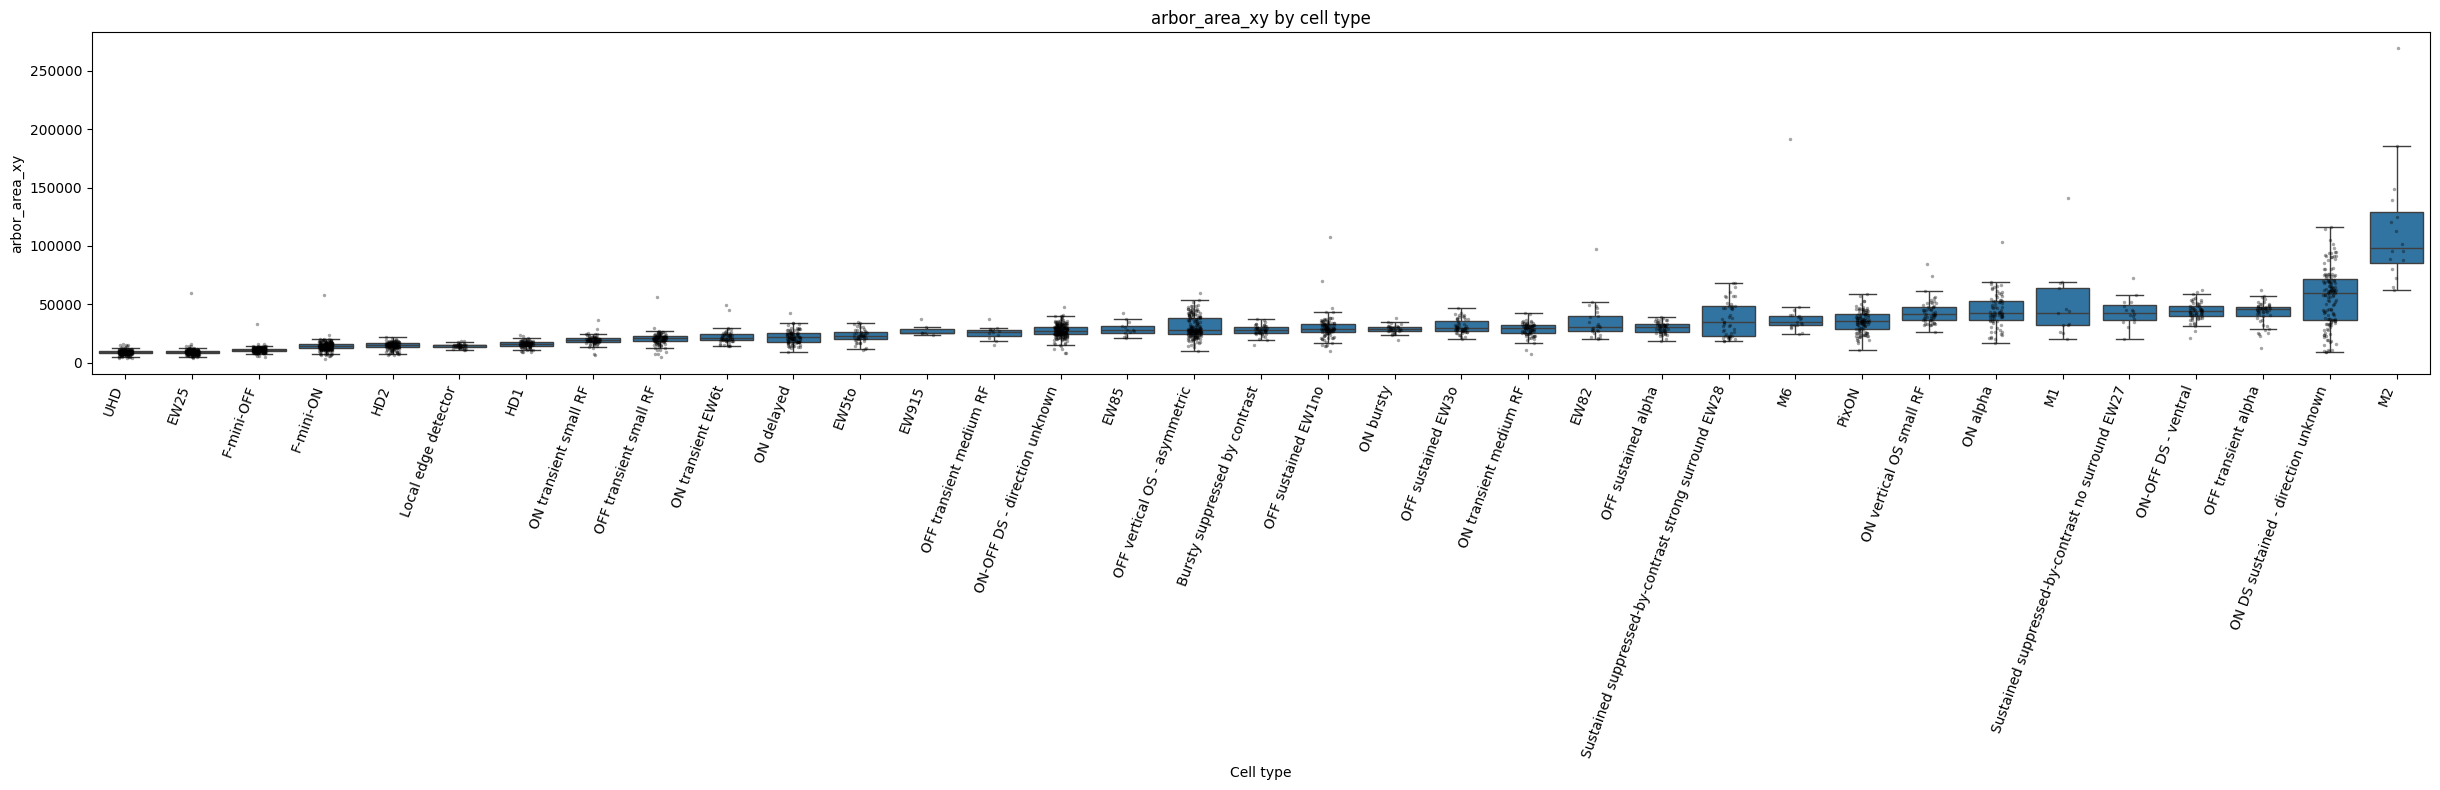

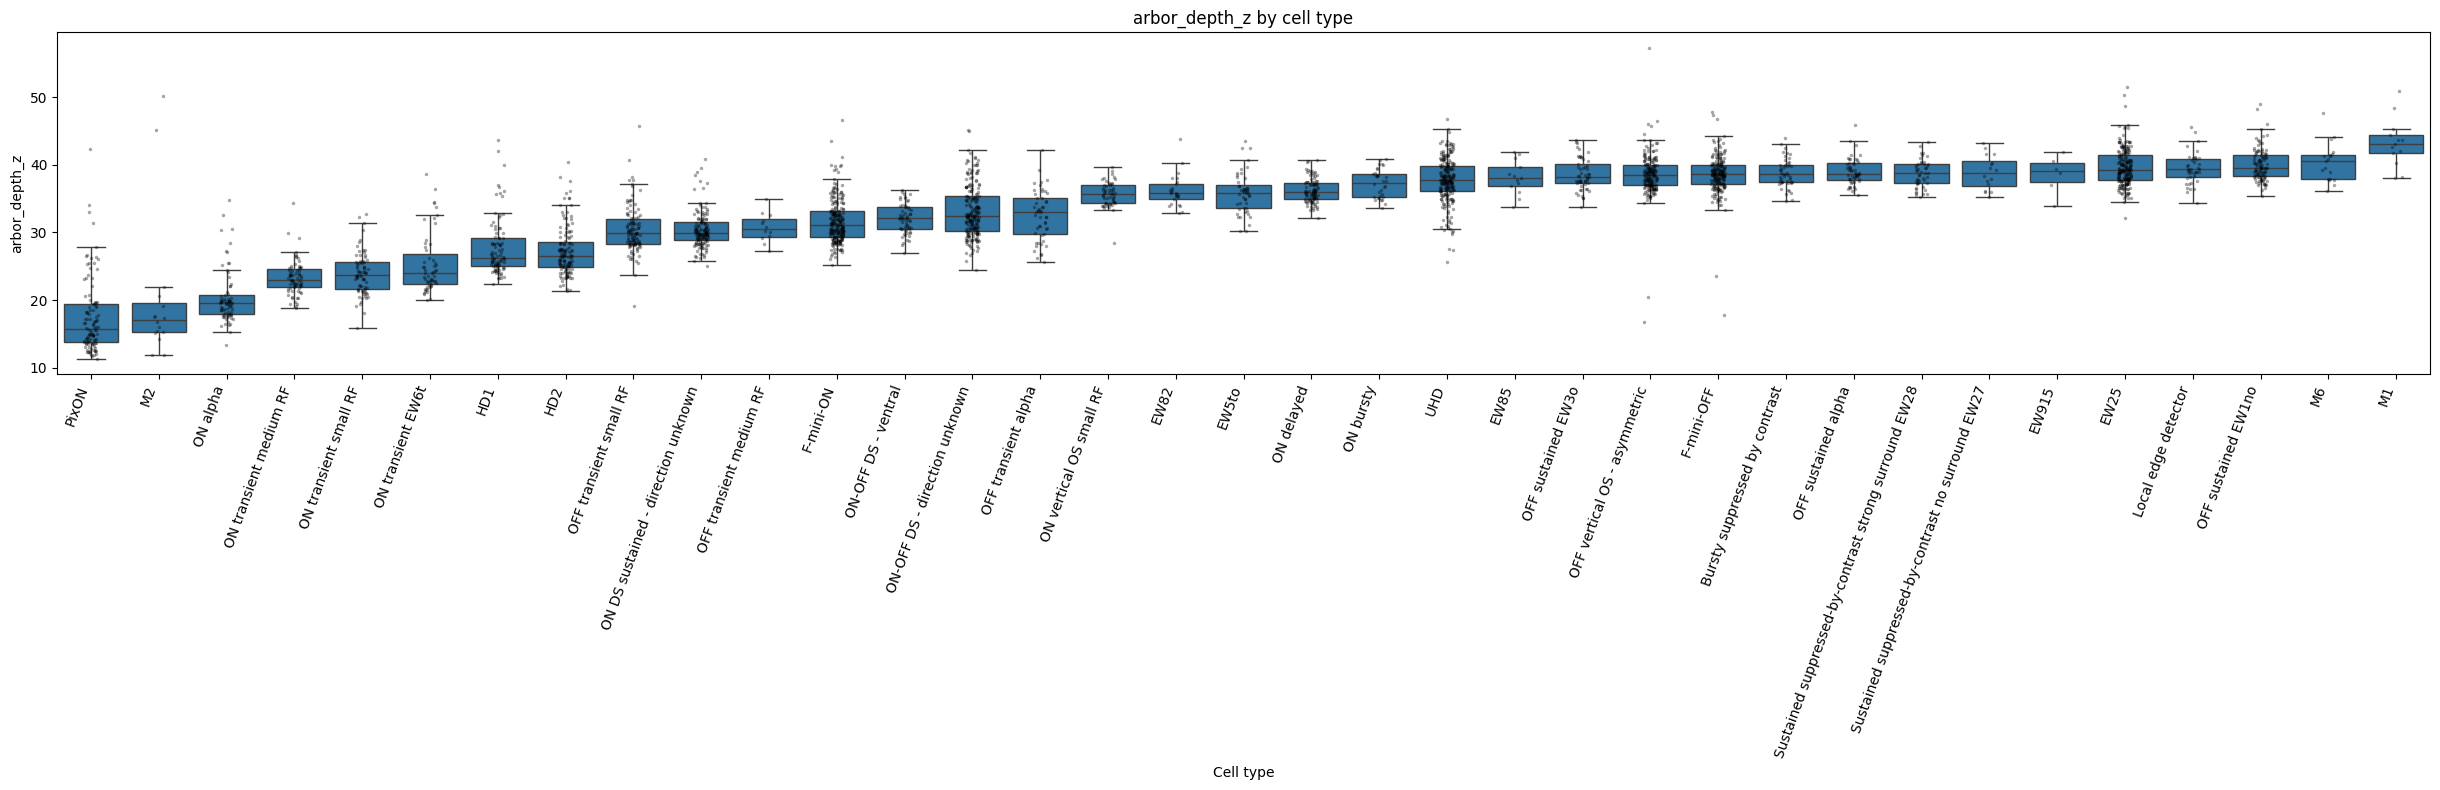

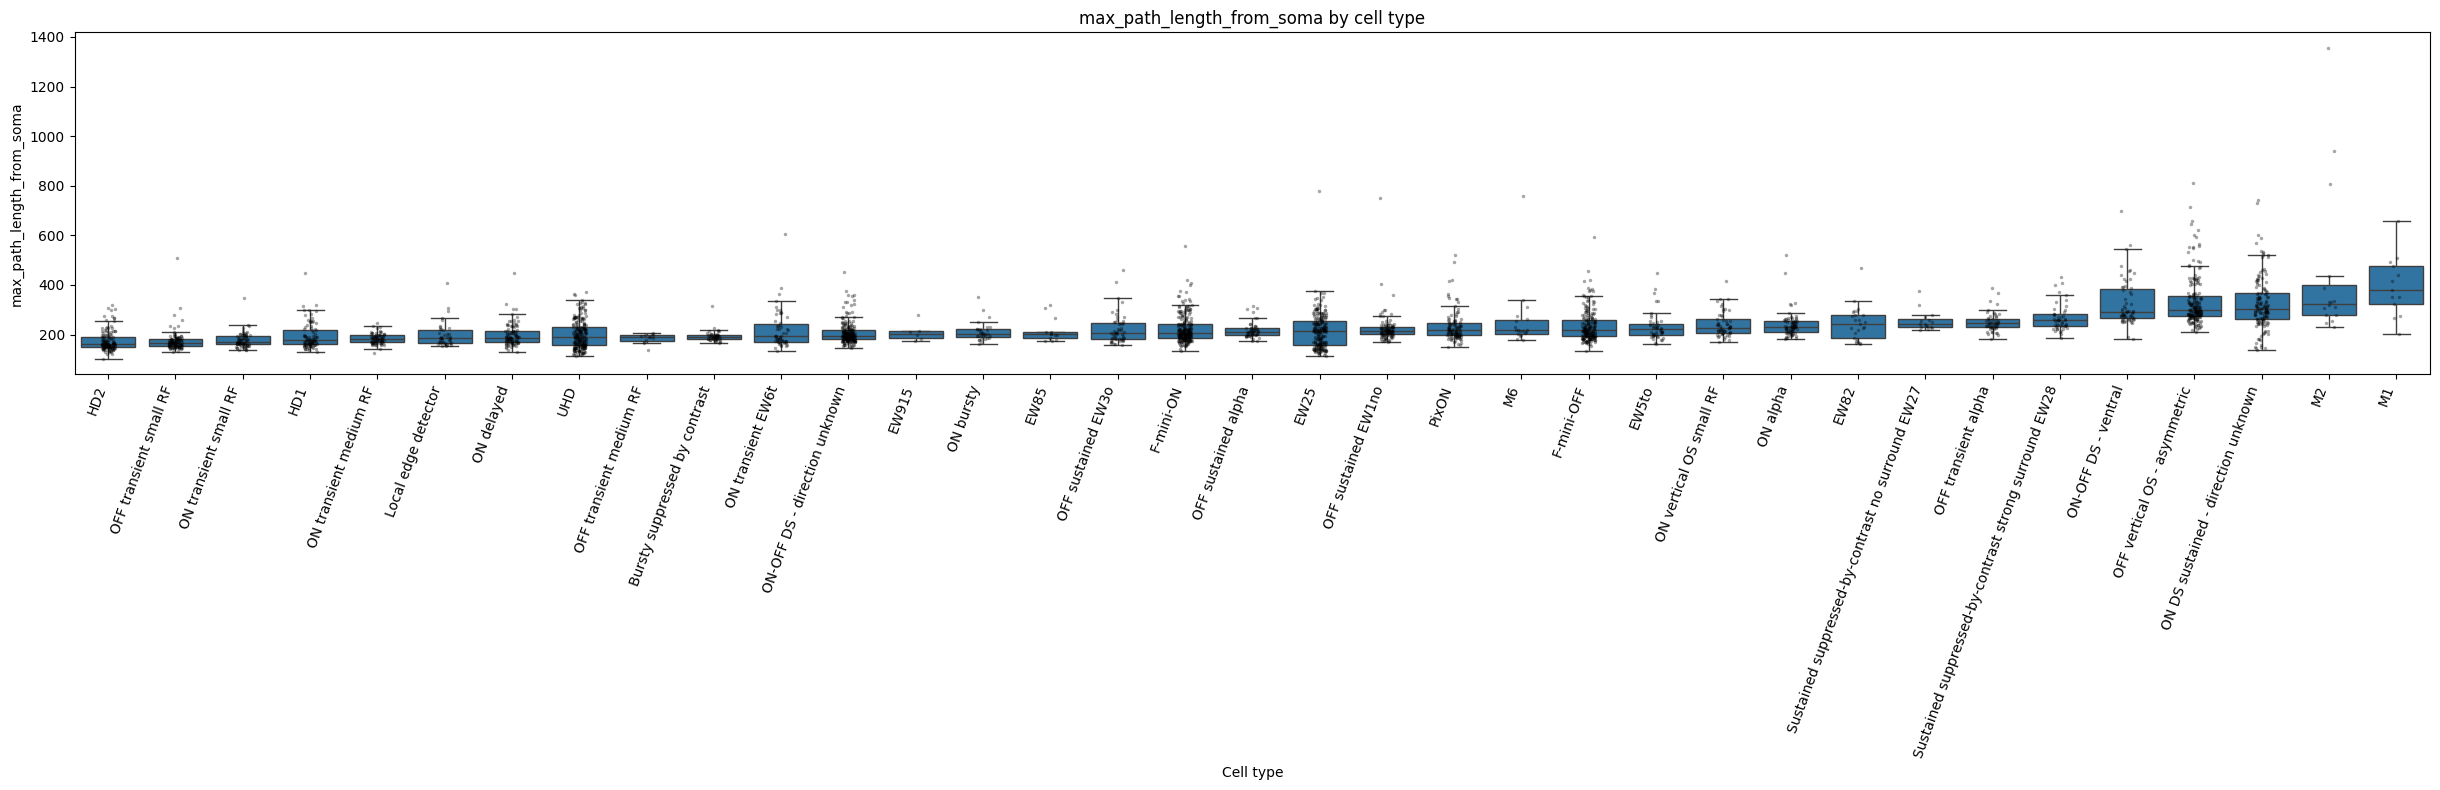

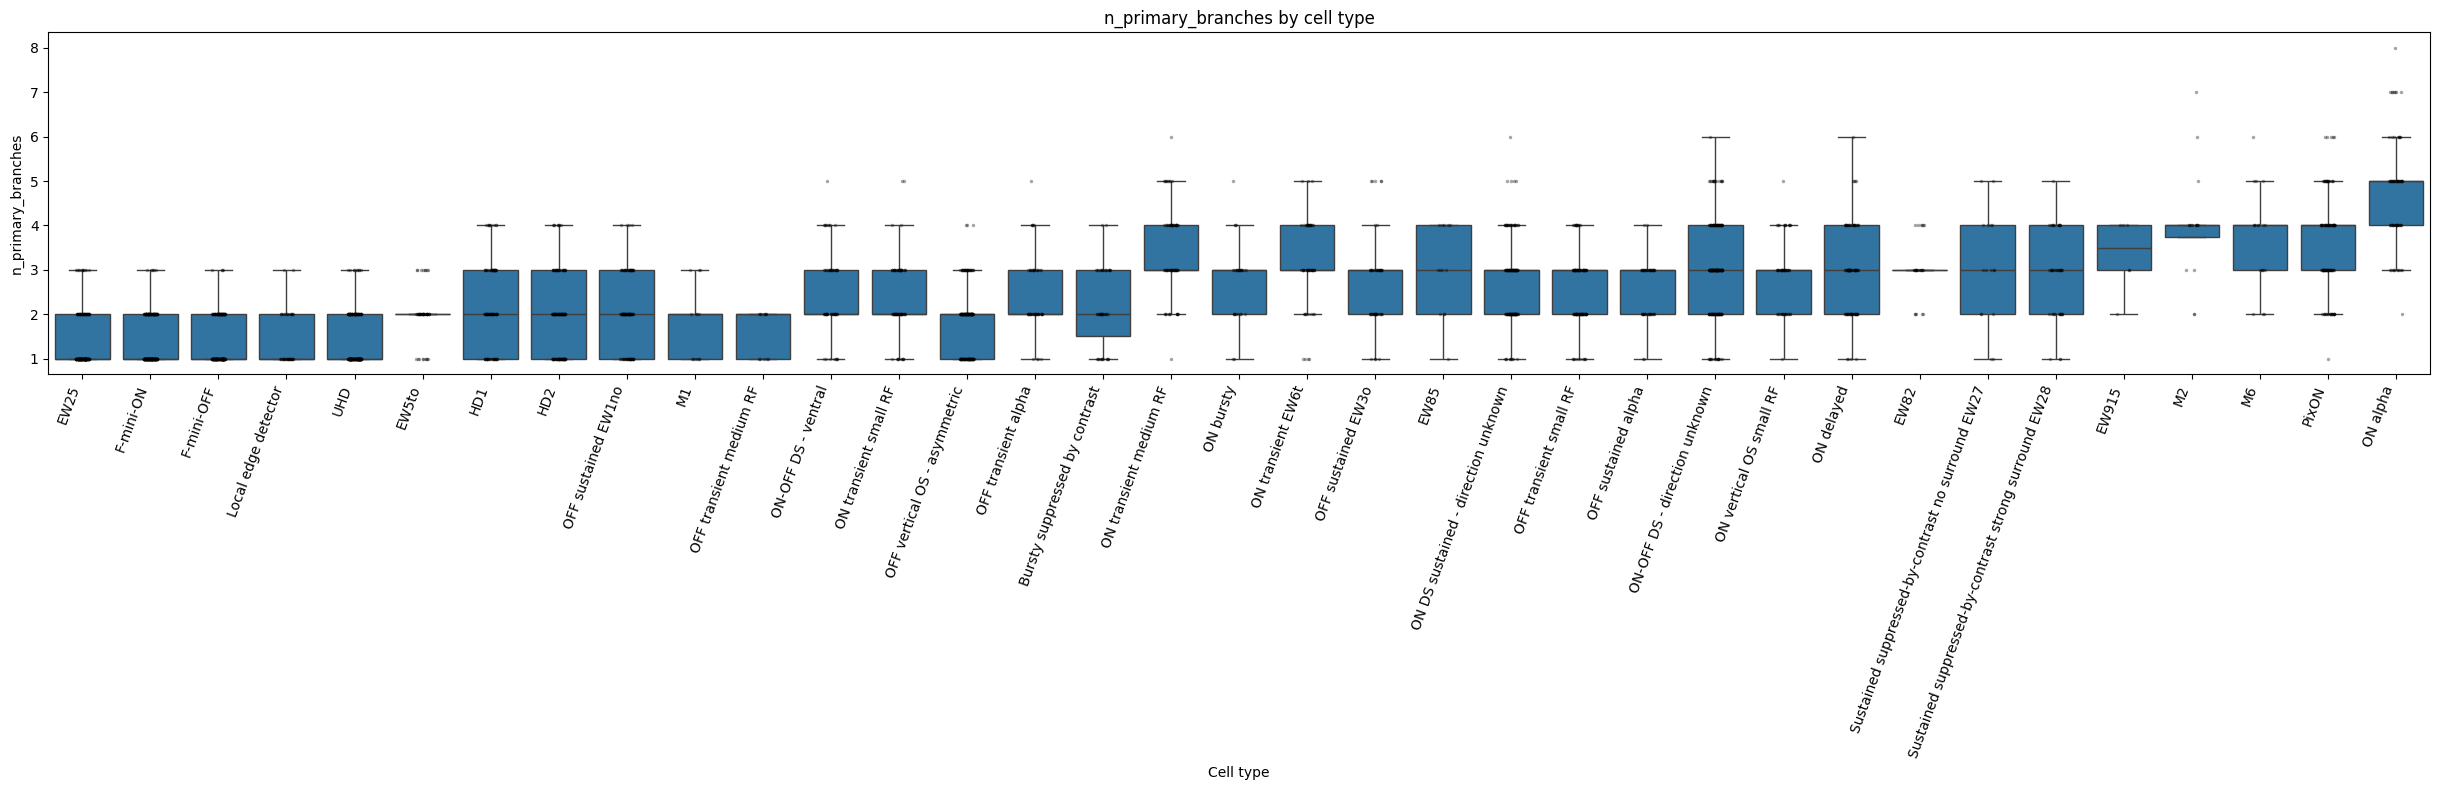

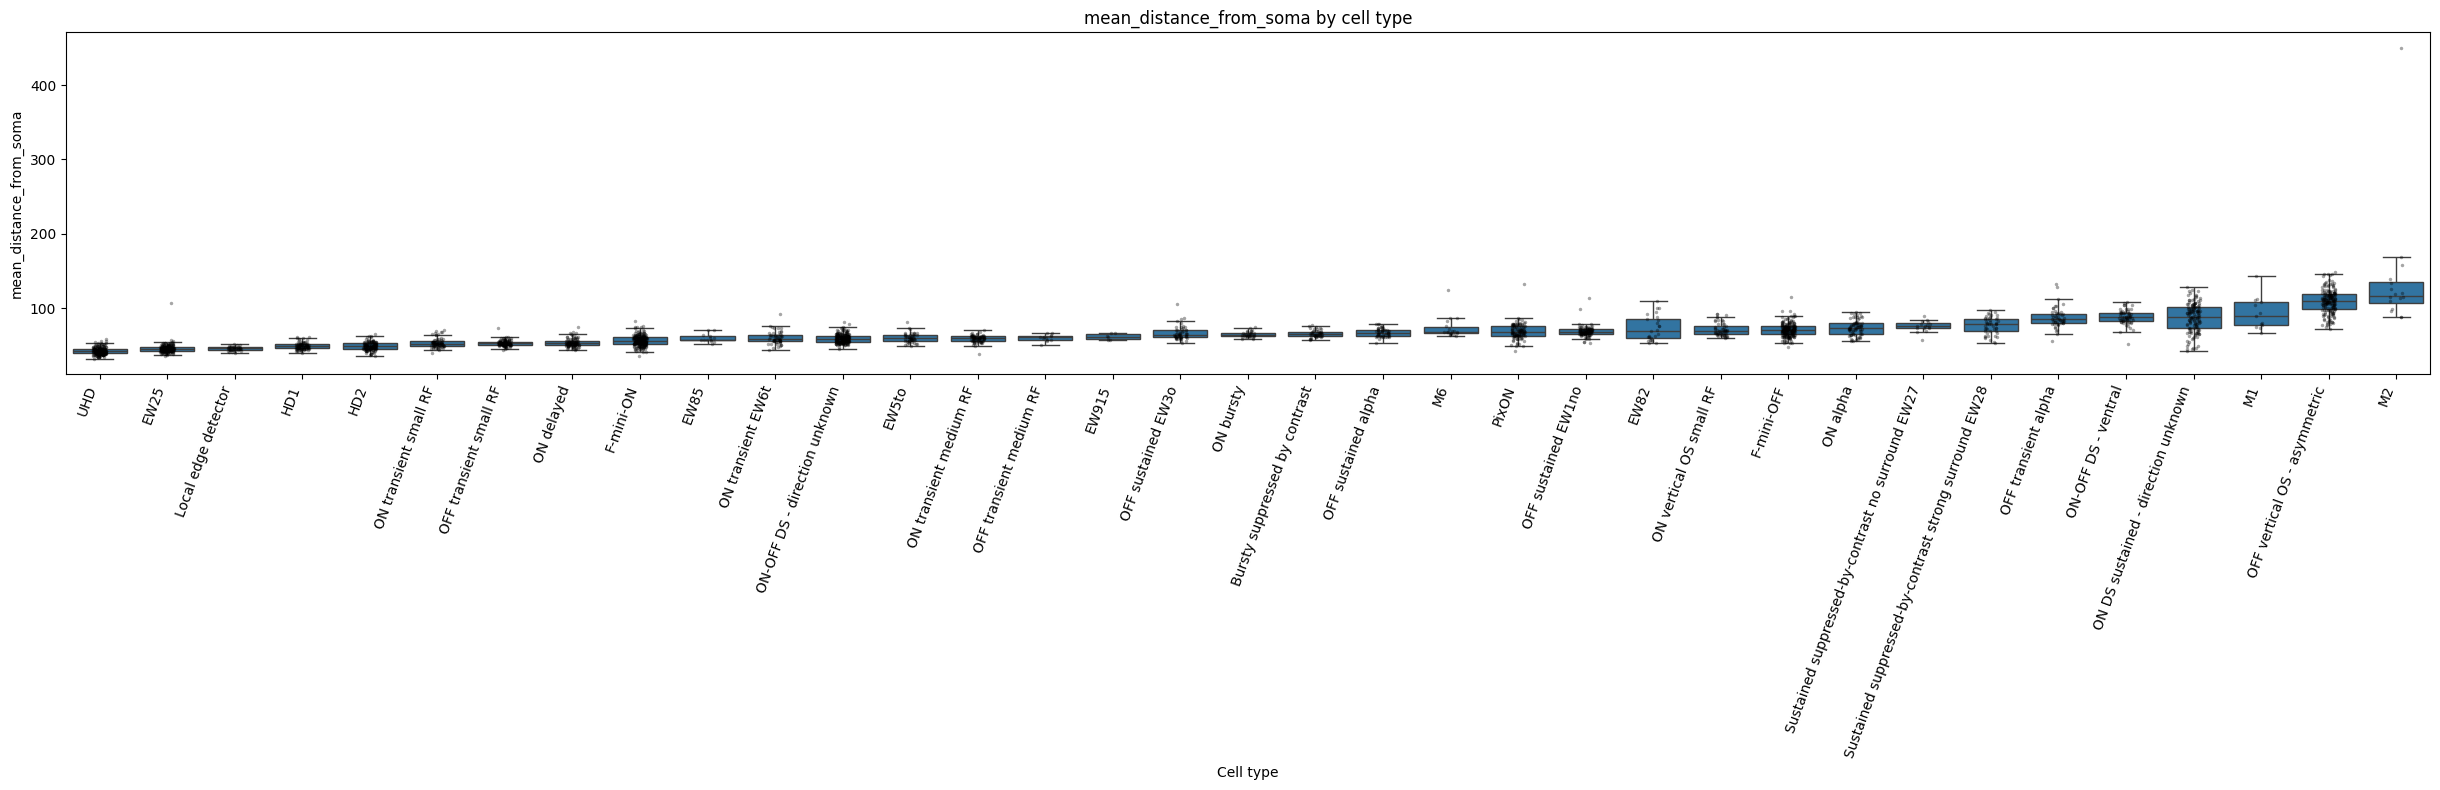

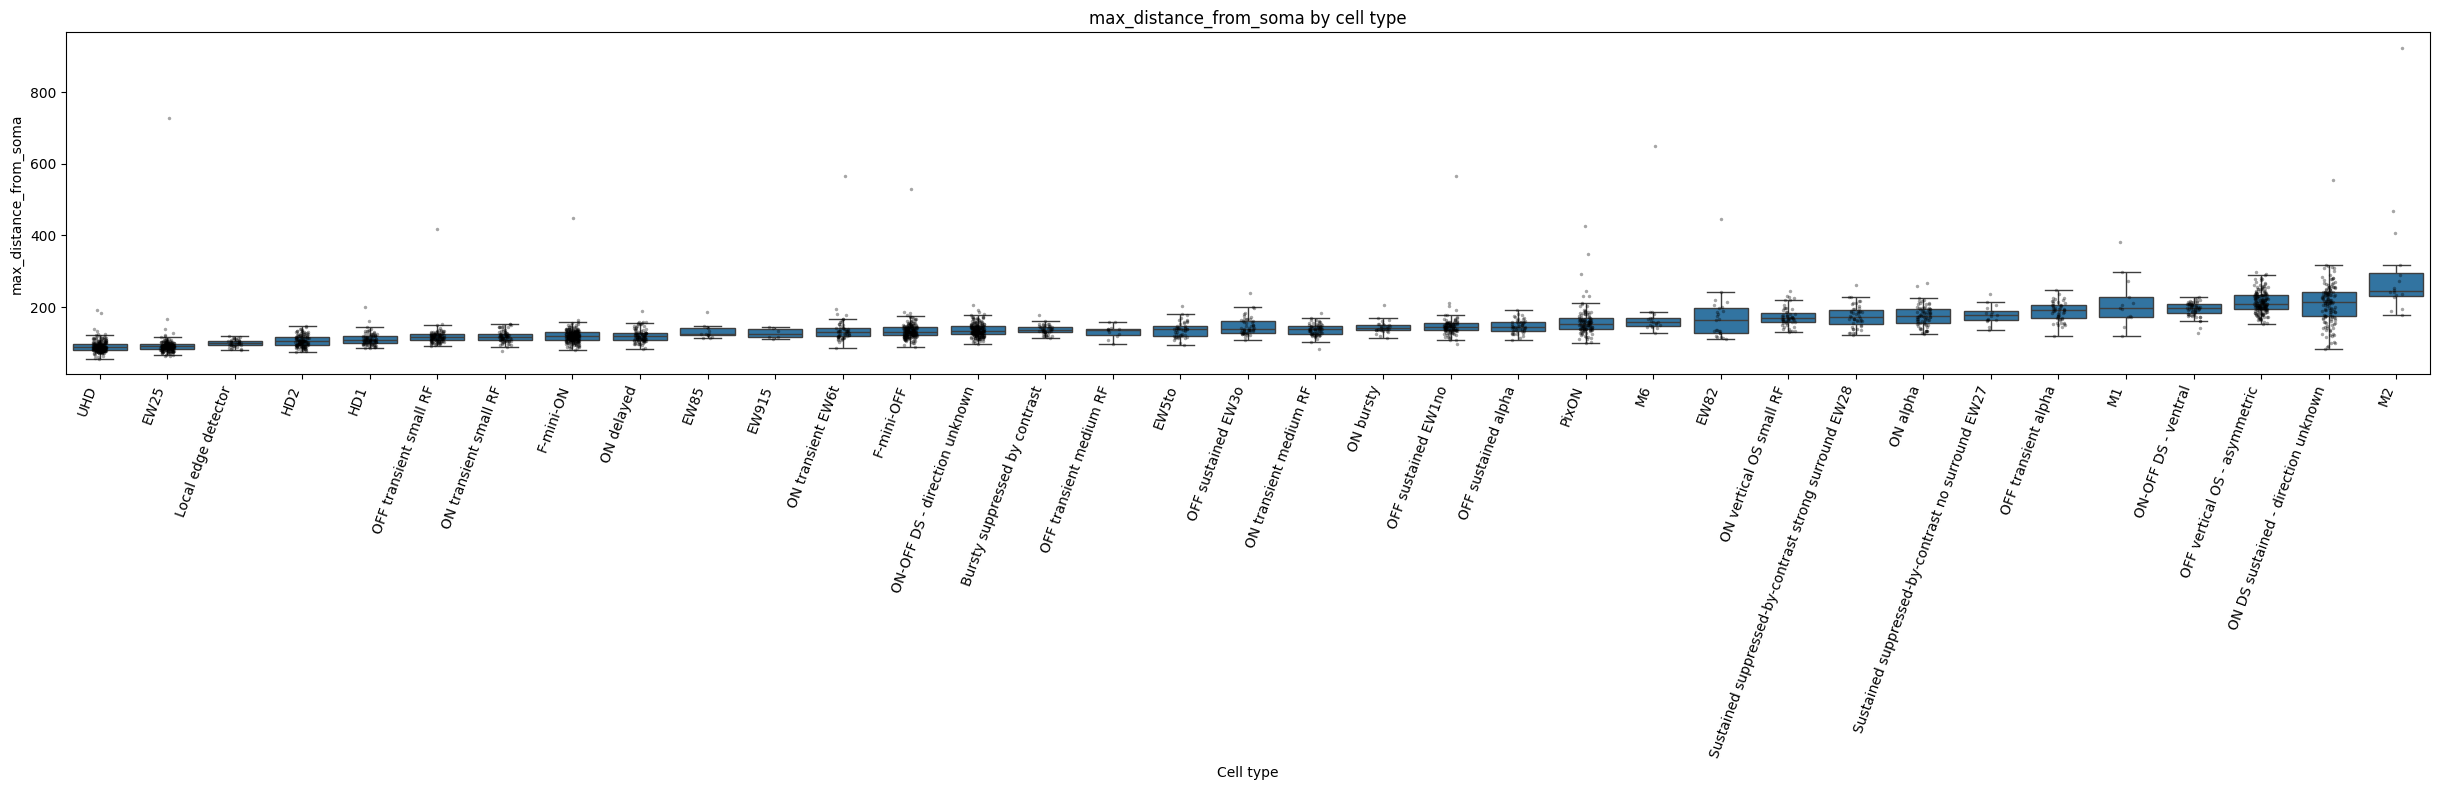

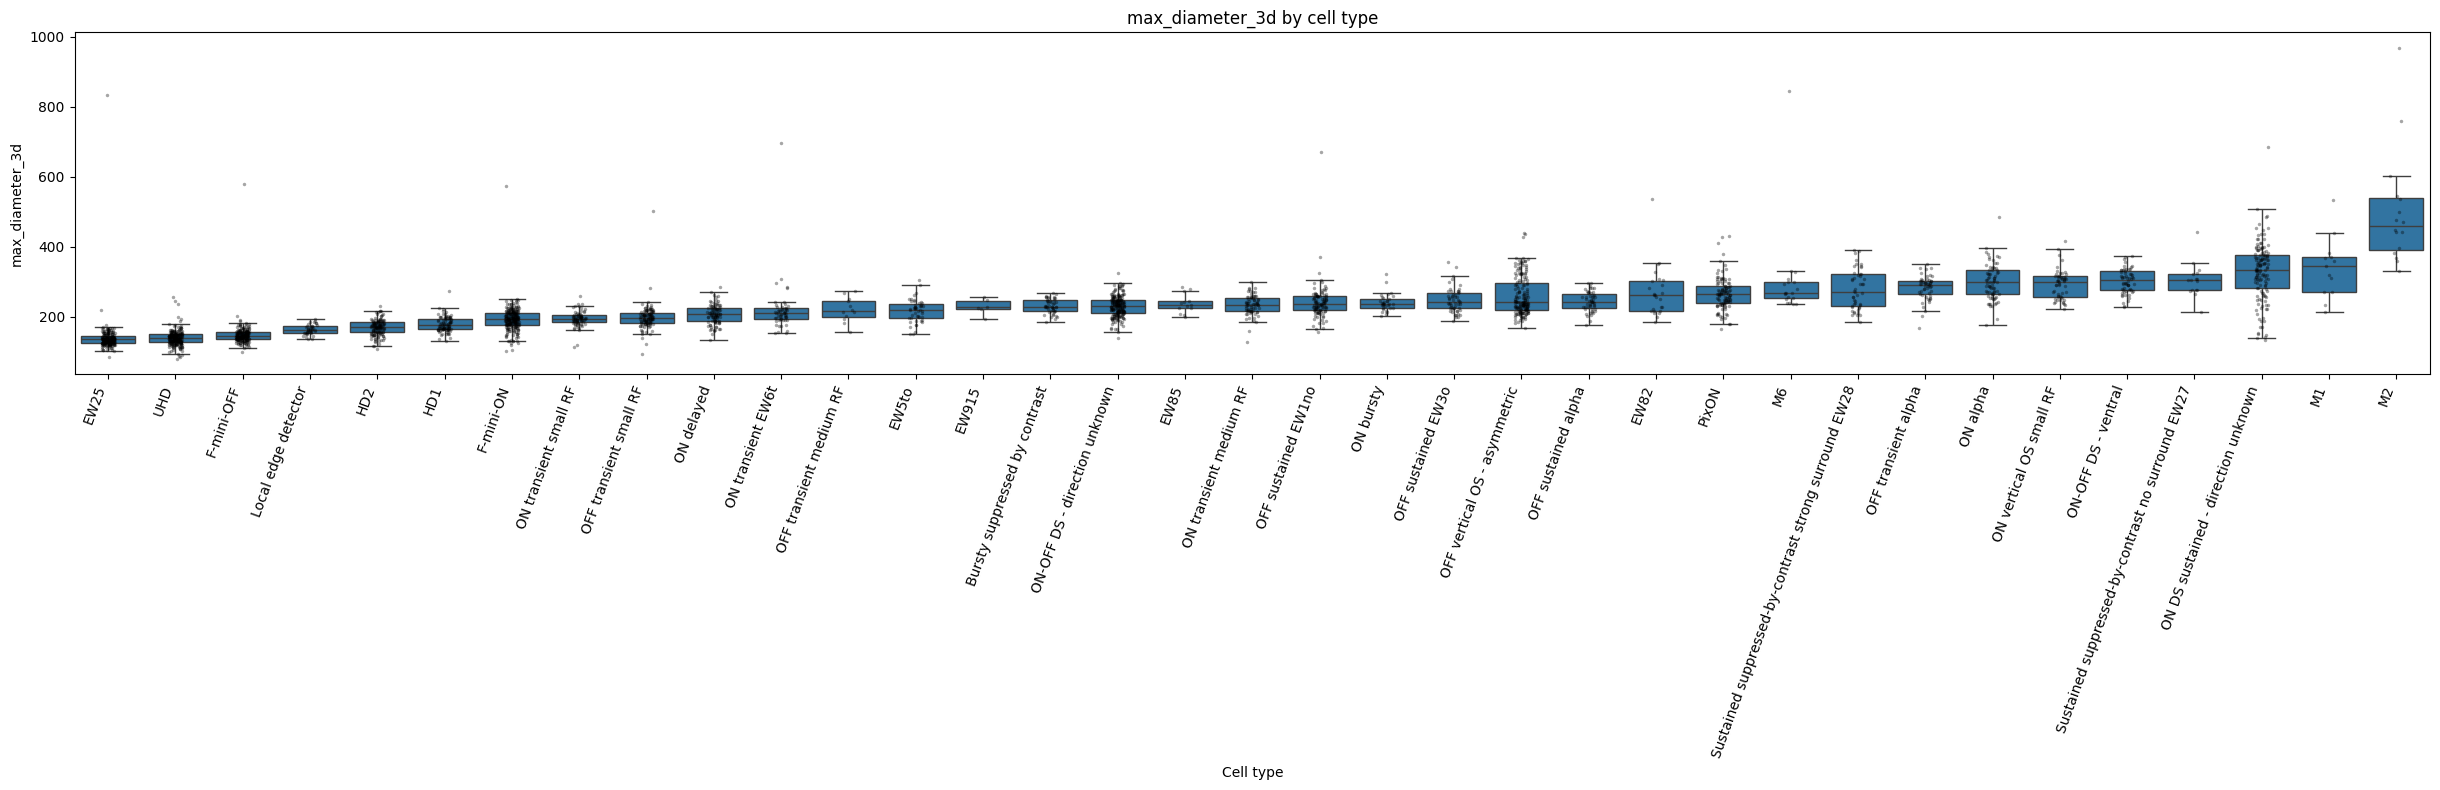

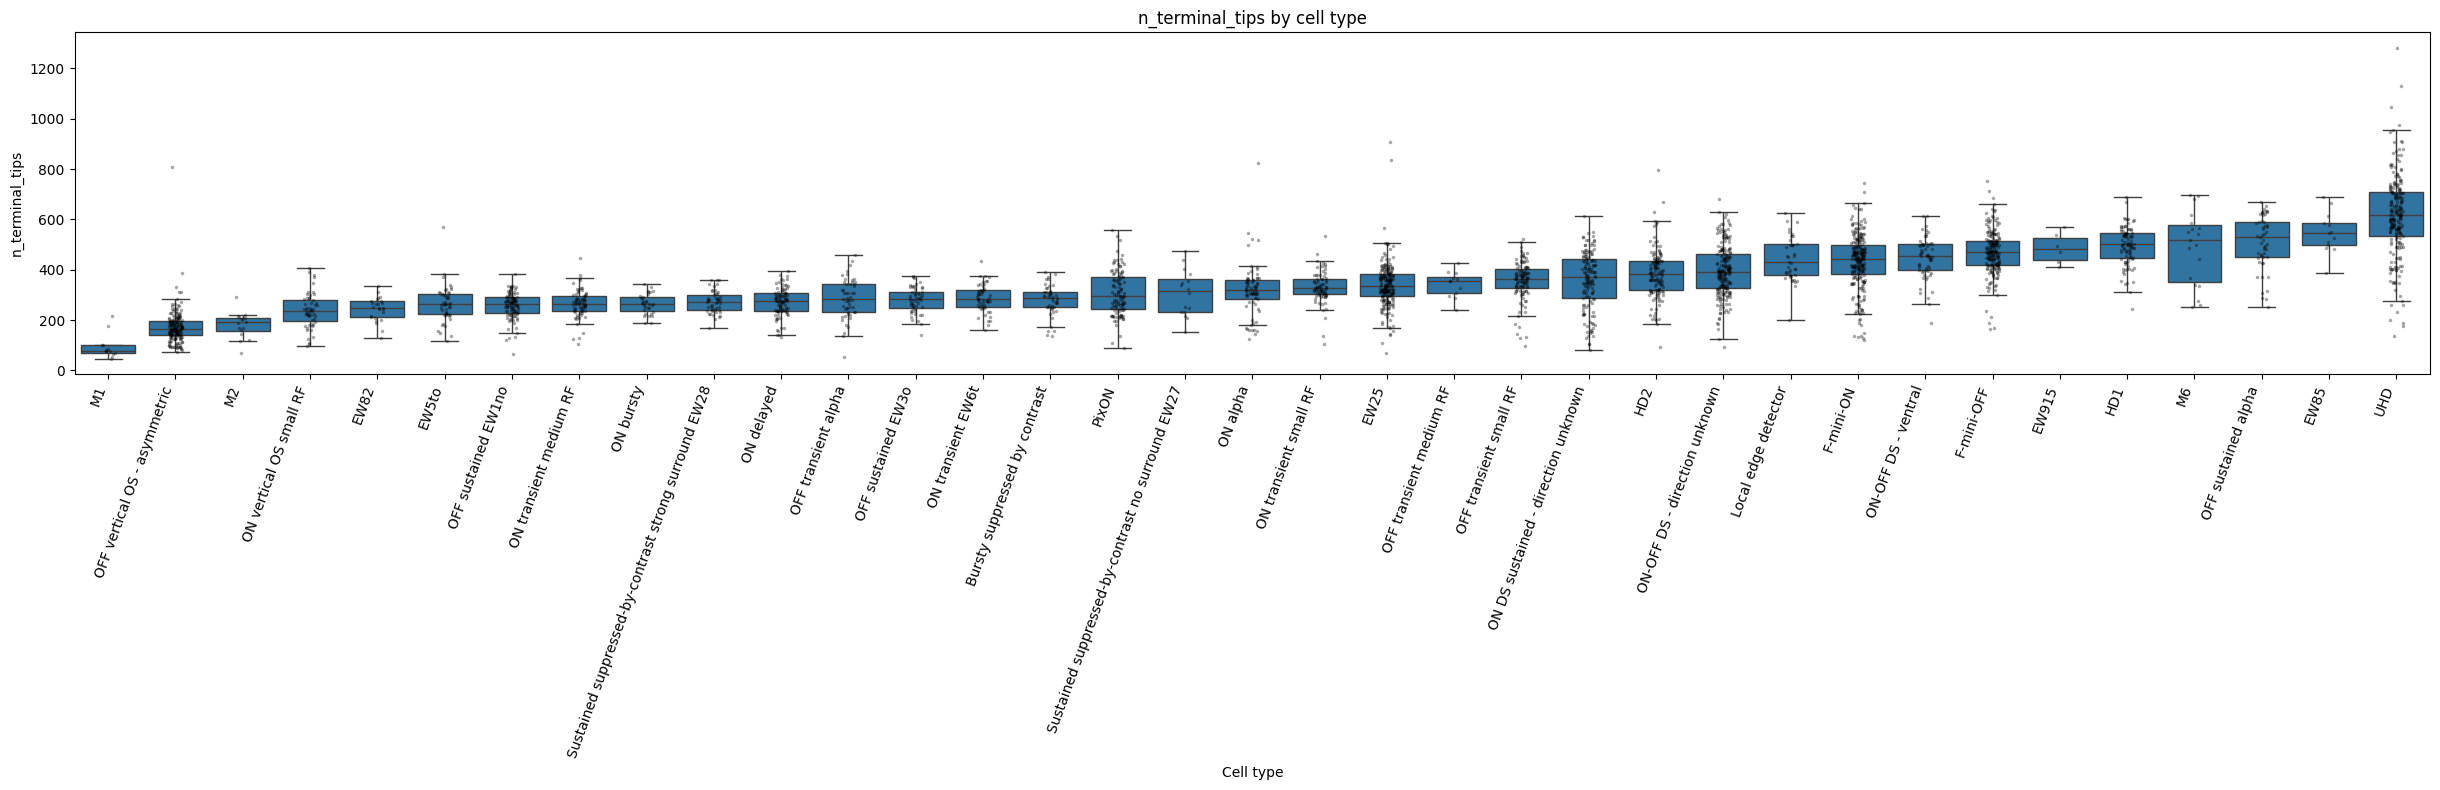

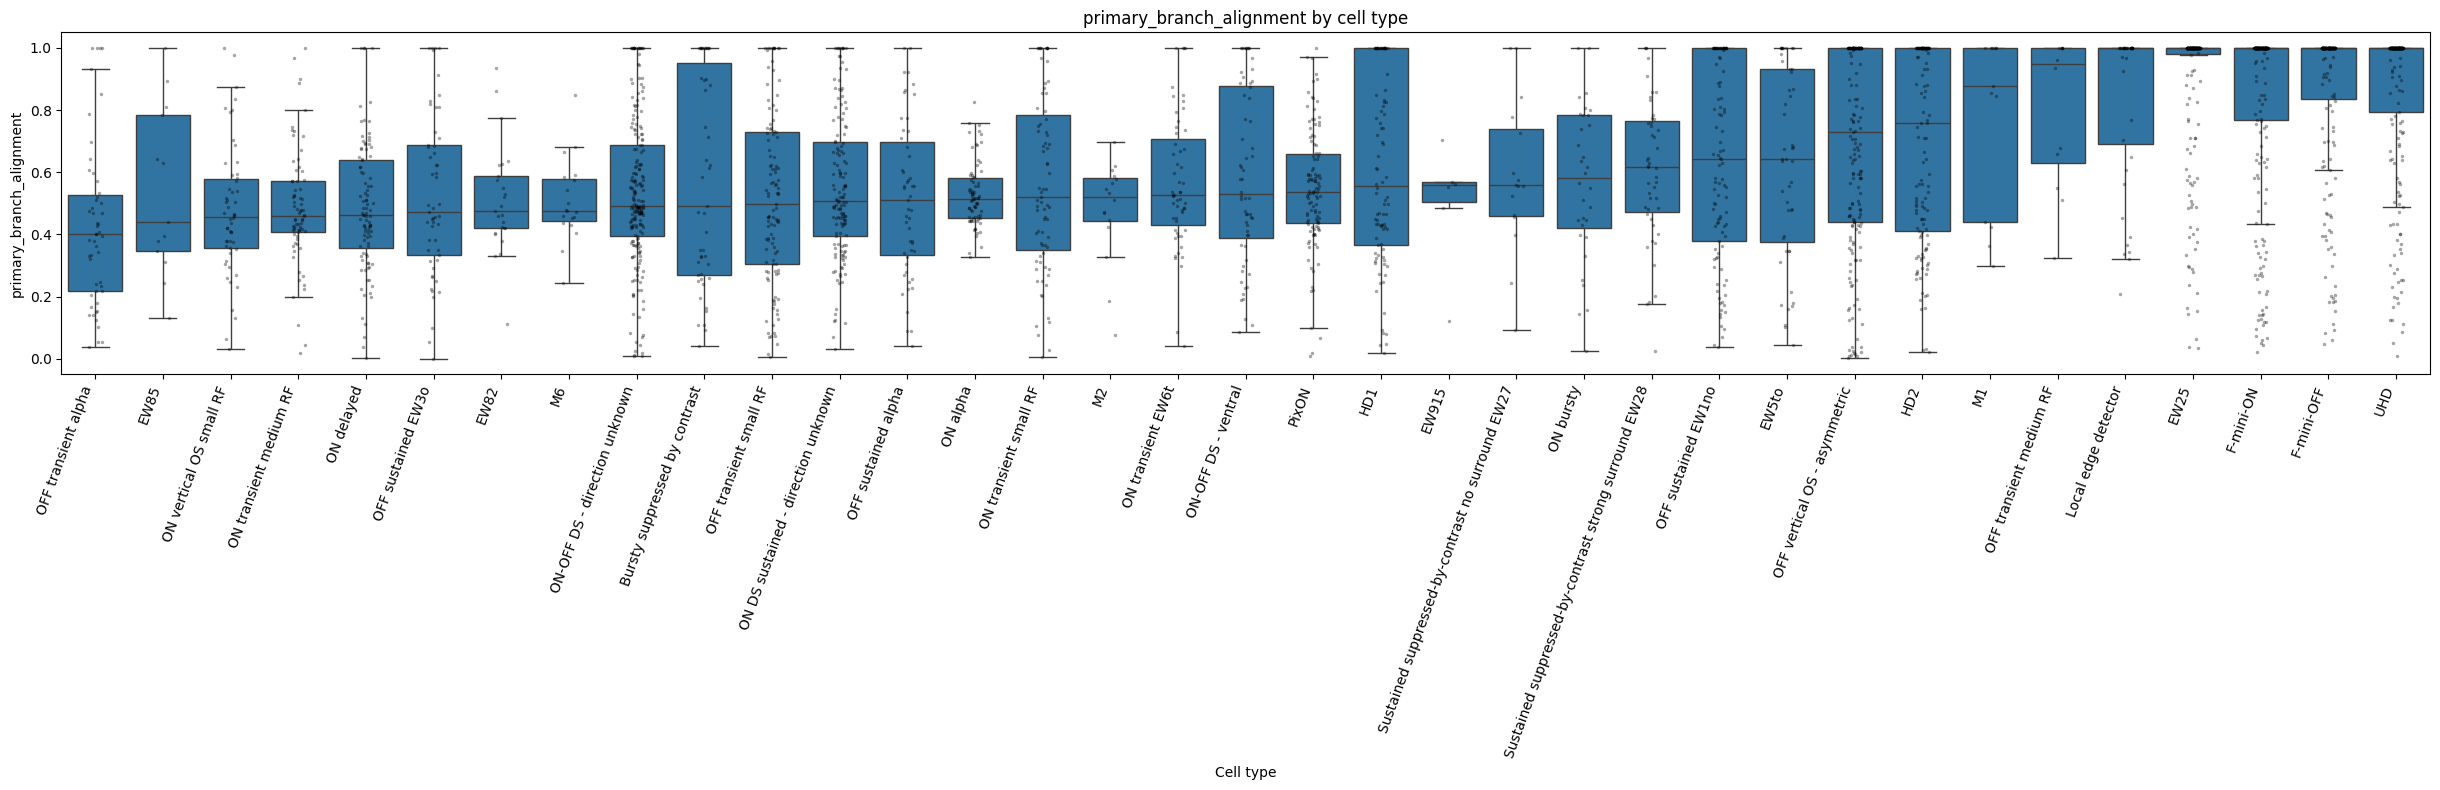

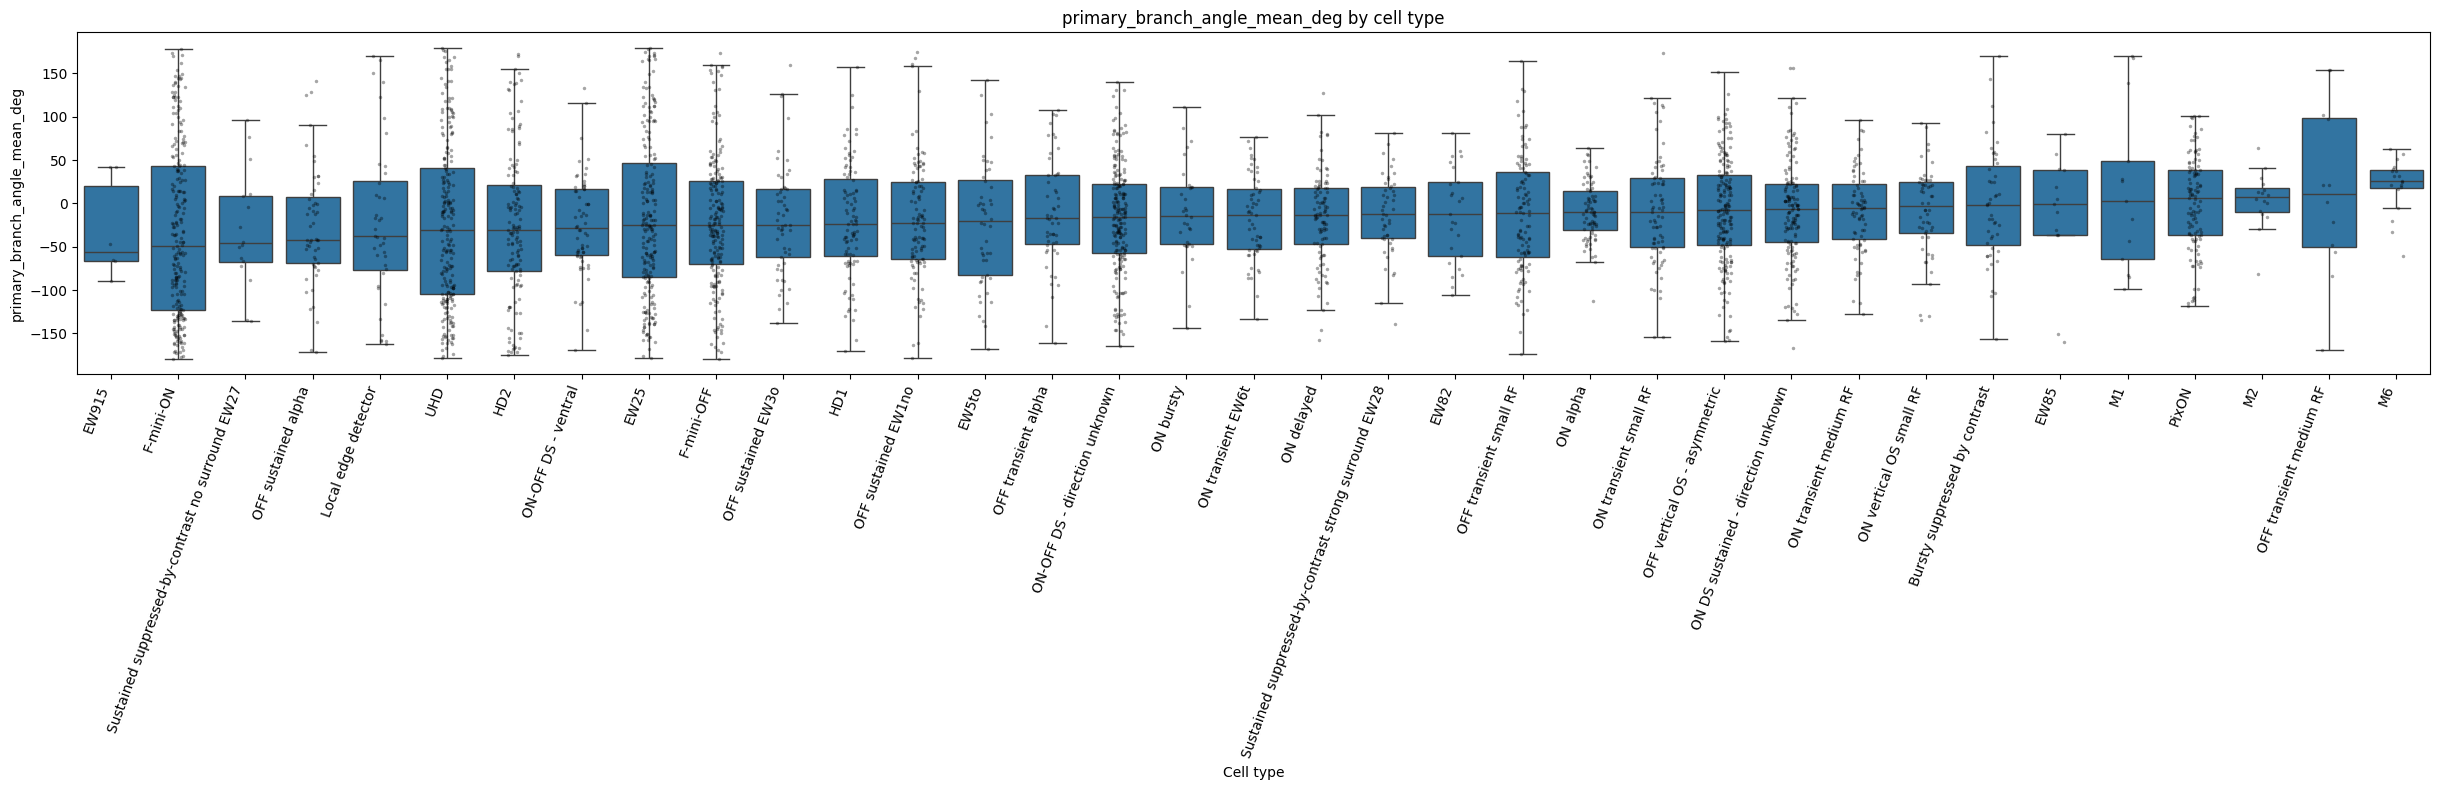

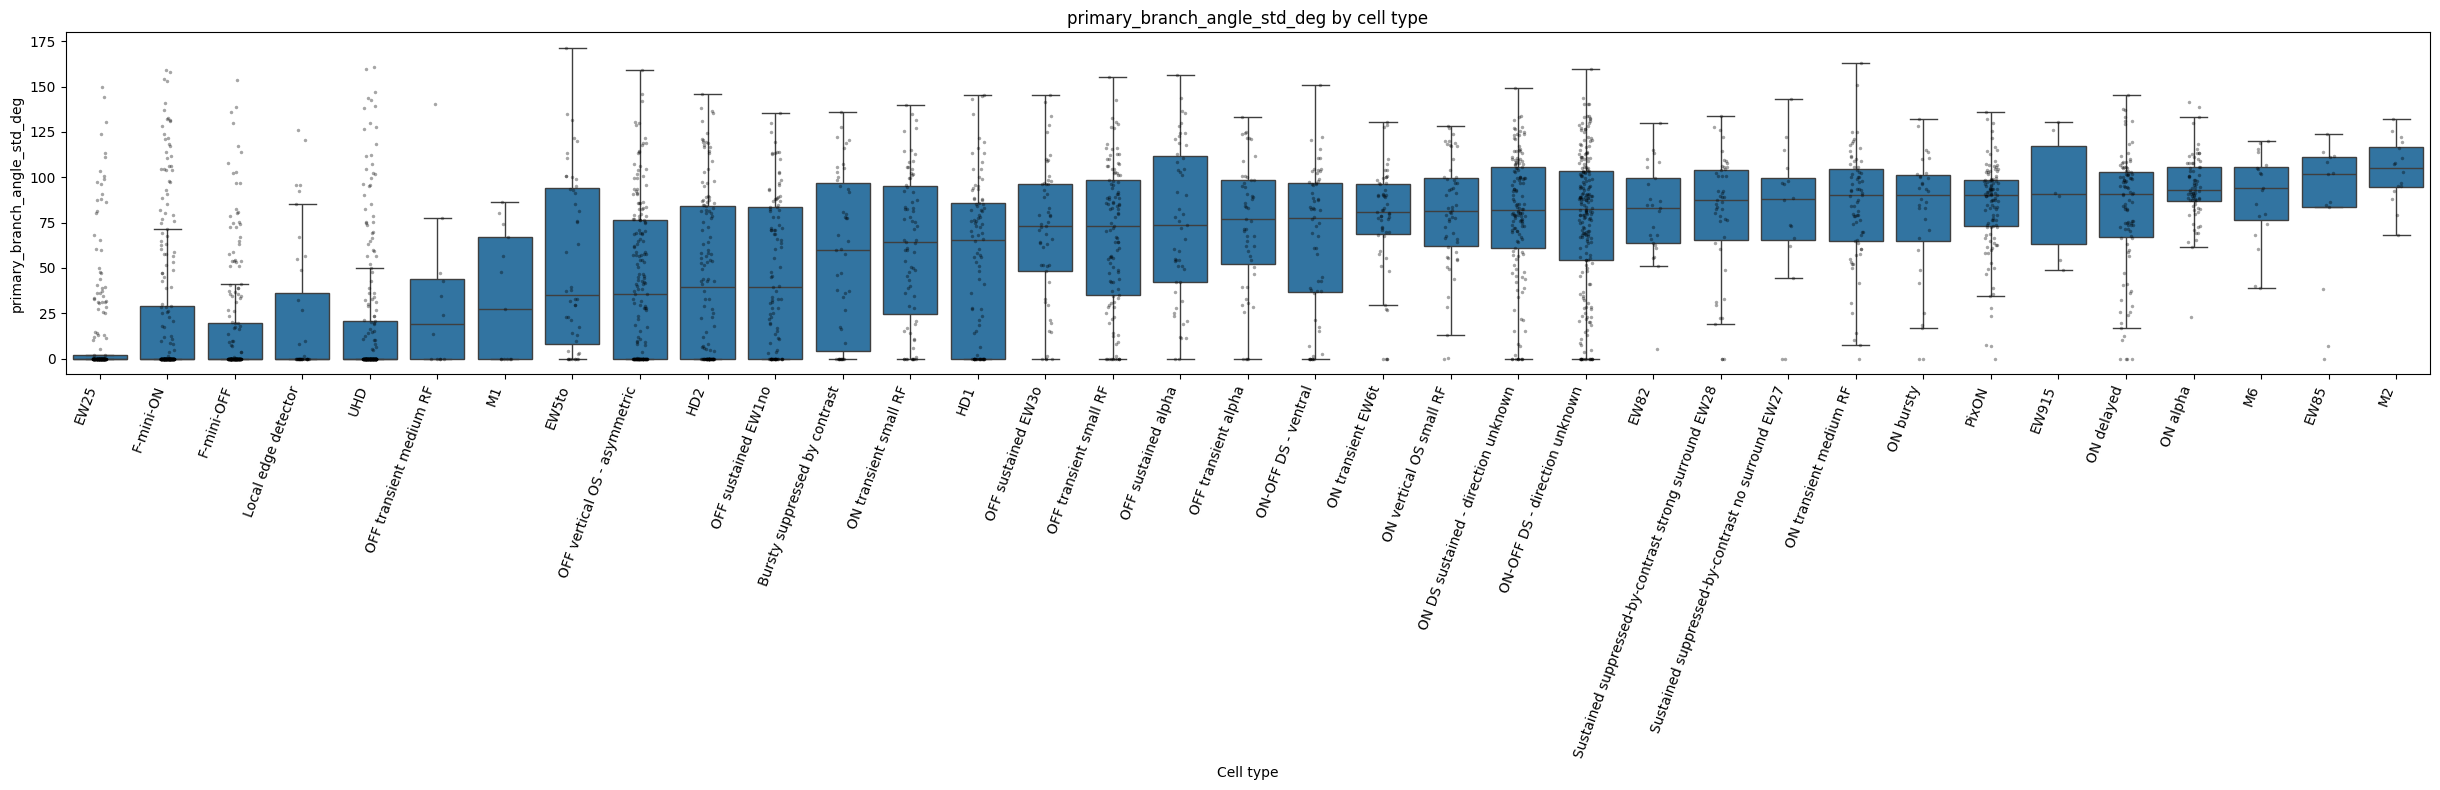

In [31]:
for feature in feature_cols:
    data = plot_df[
        ["celltype_final", feature]
    ].dropna()

    # Order cell types by median feature value
    order = (
        data.groupby("celltype_final")[feature]
        .median()
        .sort_values()
        .index
    )

    plt.figure(figsize=(max(10, len(order) * 0.7), 8))

    sns.boxplot(
        data=data,
        x="celltype_final",
        y=feature,
        order=order,
        showfliers=False
    )

    sns.stripplot(
        data=data,
        x="celltype_final",
        y=feature,
        order=order,
        color="black",
        alpha=0.35,
        size=2.5,
        jitter=True
    )

    plt.title(f"{feature} by cell type")
    plt.xlabel("Cell type")
    plt.ylabel(feature)
    plt.xticks(rotation=70, ha="right")
    plt.tight_layout()
    plt.show()

In [27]:
results = []

for feature in feature_cols:
    data = plot_df[
        ["celltype_final", feature]
    ].dropna()

    groups = [
        group[feature].to_numpy()
        for _, group in data.groupby("celltype_final")
        if len(group) > 0
    ]

    # Need at least two groups with observations
    if len(groups) < 2:
        continue

    # The test is not informative if all observations are identical
    if len(np.unique(data[feature])) < 2:
        statistic, p_value = np.nan, np.nan
    else:
        statistic, p_value = kruskal(*groups)

    results.append({
        "feature": feature,
        "n_cells": len(data),
        "n_cell_types": len(groups),
        "kruskal_statistic": statistic,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# Correct for testing multiple features
valid = results_df["p_value"].notna()

results_df["p_adjusted"] = np.nan

if valid.any():
    results_df.loc[valid, "p_adjusted"] = multipletests(
        results_df.loc[valid, "p_value"],
        method="fdr_bh"
    )[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05

results_df = results_df.sort_values("p_adjusted")

display(results_df)

,feature,n_cells,n_cell_types,kruskal_statistic,p_value,p_adjusted,significant
0,arbor_area_xy,2915,39,2377.092624,0.000000e+00,0.000000e+00,True
1,arbor_depth_z,2915,39,2149.476640,0.000000e+00,0.000000e+00,True
5,max_distance_from_soma,2915,39,2163.745742,0.000000e+00,0.000000e+00,True
4,mean_distance_from_soma,2915,39,2353.818937,0.000000e+00,0.000000e+00,True
6,max_diameter_3d,2915,39,2226.841495,0.000000e+00,0.000000e+00,True
7,n_terminal_tips,2915,39,1744.091773,0.000000e+00,0.000000e+00,True
3,n_primary_branches,2915,39,1442.138969,3.102501e-278,4.875359e-278,True
2,max_path_length_from_soma,2915,39,1139.605648,2.230461e-214,3.066884e-214,True
10,primary_branch_angle_std_deg,2915,39,1002.433415,1.362444e-185,1.665209e-185,True
8,primary_branch_alignment,2915,39,750.740911,3.419035e-133,3.760939e-133,True


## Loading SWC samples from huggingface

In [62]:
config_path = f"../configs/{TRIAL}.json"

In [66]:
# skeletons_path = (
#     Path(config['data']['path'])
#     / "skeletons"
#     / "720575940537162675"
#     / "features.npy"
# )   

# sk.io.load_npz(skeletons_path)


In [11]:
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "preprocessing" else Path.cwd()

data_path = ROOT_DIR / "data" / "raw" / "data"
swc_dir = data_path / "swc-huggingface" / "swc"

columns = [
    "id", "type", "x", "y", "z", "radius", "parent"
]

# Dictionary: neuron ID -> DataFrame
neurons_dict = {}

for file in swc_dir.glob("*.swc"):
    neuron_id = file.stem

    neurons_dict[neuron_id] = pd.read_csv(
        file,
        sep=r"\s+",
        comment="#",
        header=None,
        names=columns
    )

print(f"Number of neurons: {len(neurons_dict)}")

# Example: inspect the first neuron
if neurons_dict:
    first_id = next(iter(neurons_dict))
    print("Neuron ID:", first_id)
    print(neurons_dict[first_id].head())

Number of neurons: 161
Neuron ID: 720575940543904349
   id  type           x           y          z    radius  parent
0   1    -1  402.606633  325.675258  22.812330  0.231805      -1
1   2     3  402.692952  325.830844  22.784872  0.198952       1
2   3     3  402.747972  326.025513  22.750869  0.205813       2
3   4     3  402.802825  326.173135  22.602728  0.220660       3
4   5     3  402.815291  326.342778  22.437584  0.174121       4


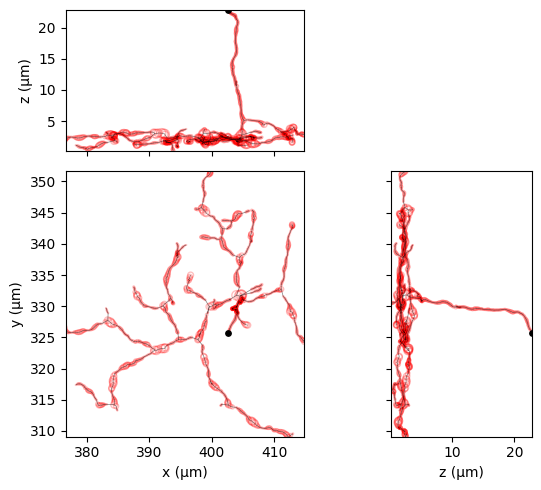

In [15]:
skel = sk.io.load_skeleton_swc(swc_dir / "720575940543904349.swc")
fig, ax = sk.plot.threeviews(
    skel,
    scale=1,
    unit="μm",
    figsize=(7, 5)
)

(<Figure size 600x600 with 1 Axes>, <Axes: xlabel='x (μm)', ylabel='y (μm)'>)

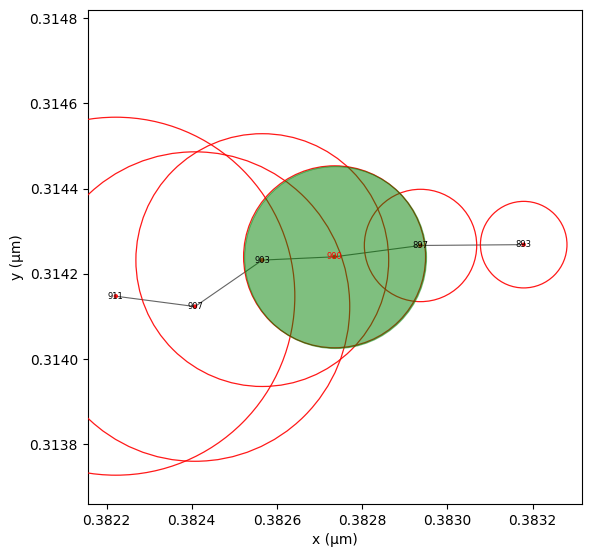

In [22]:
sk.plot.node_details(skel, node_id=900, multiplier=2.5, 
draw_edges=True, show_node_ids=True, scale=1e-3, unit="μm")

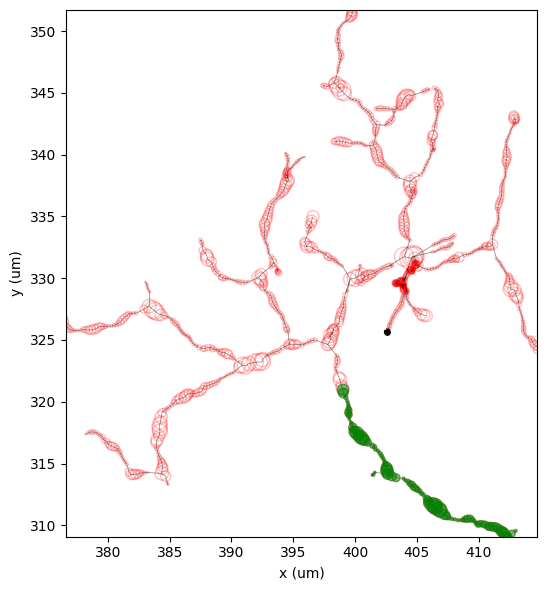

In [26]:
axon_maybe = skel.extract_neurites(root=500)
fig, ax = sk.plot2d(skel, highlight_nodes=axon_maybe)